### **CELL 1: OCI Environment Setup, Strict Determinism & Publication Plot Standards**

In [1]:
# ==============================================================================
# CELL 1: OCI ENVIRONMENT SETUP, STRICT DETERMINISM & TITLE-FREE PLOT STANDARDS
# ==============================================================================
import sys, os, random, time, shutil, subprocess, tempfile, gc, types, warnings, threading
import hashlib, urllib.request, zipfile, json
from datetime import datetime, timezone
from pathlib import Path

warnings.filterwarnings('ignore')

def pip_install(*arguments):
    completed = subprocess.run(
        [sys.executable, '-m', 'pip', *arguments], text=True,
        stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
    )
    if completed.returncode:
        print(completed.stdout)
        raise RuntimeError(f'pip failed with exit code {completed.returncode}.')

def is_pkg_installed(mod_name):
    try:
        res = subprocess.run([sys.executable, '-c', f'import {mod_name}'], capture_output=True, text=True)
        return res.returncode == 0
    except Exception:
        return False

def check_torch_cuda():
    try:
        res = subprocess.run([sys.executable, '-c', 'import torch; print(torch.cuda.is_available())'], capture_output=True, text=True)
        return res.stdout.strip() == 'True'
    except Exception:
        return False

print("⚙️ Checking and Installing Dependencies...")
nvidia_detected = shutil.which('nvidia-smi') is not None
has_cuda_torch = check_torch_cuda()
has_working_torch = is_pkg_installed('torch')

if nvidia_detected and not has_cuda_torch:
    pip_install('install', '--upgrade', '--index-url', 'https://download.pytorch.org/whl/cu128', 'torch>=2.4,<2.15')
elif not has_working_torch:
    pip_install('install', '--upgrade', '--extra-index-url', 'https://download.pytorch.org/whl/cpu', 'torch>=2.4,<2.15')

# Only install missing packages without overwriting in-memory C-extensions (numpy/scipy)
missing_pkgs = []
for mod_check, pkg_spec in [
    ('numpy', 'numpy>=1.24,<3'),
    ('pandas', 'pandas>=2.0,<4'),
    ('sklearn', 'scikit-learn>=1.3,<2'),
    ('xgboost', 'xgboost>=2.0,<4'),
    ('matplotlib', 'matplotlib>=3.7,<4'),
    ('seaborn', 'seaborn'),
    ('scipy', 'scipy'),
    ('tabulate', 'tabulate'),
    ('torch_geometric', 'torch-geometric>=2.5,<2.9'),
    ('tqdm', 'tqdm')
]:
    if not is_pkg_installed(mod_check):
        missing_pkgs.append(pkg_spec)

if missing_pkgs:
    pip_install('install', *missing_pkgs)

import numpy as np

# Guard against in-memory vs. on-disk NumPy C-extension ABI mismatch in active kernels
if hasattr(np, '_core') and hasattr(np._core, '_multiarray_umath'):
    if not hasattr(np._core._multiarray_umath, '_blas_supports_fpe'):
        try:
            setattr(np._core._multiarray_umath, '_blas_supports_fpe', lambda *a, **kw: False)
        except Exception:
            pass
try:
    import numpy.testing
except Exception:
    dummy_testing = types.ModuleType('numpy.testing')
    sys.modules['numpy.testing'] = dummy_testing
    np.__dict__['testing'] = dummy_testing

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from tqdm.auto import tqdm
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch_geometric.data import HeteroData
from torch_geometric.nn import GATConv, SAGEConv, GCNConv, HeteroConv
from sklearn.metrics import (
    precision_recall_curve, average_precision_score,
    roc_curve, auc, confusion_matrix, f1_score, roc_auc_score, matthews_corrcoef
)
from sklearn.model_selection import train_test_split
import xgboost as xgb

# ------------------------------------------------------------------------------
# STRICT GLOBAL & PER-MODEL DETERMINISM
# ------------------------------------------------------------------------------
SEED = 42
JOURNAL_SEEDS = [42, 123, 26]

def lock_seed(seed=SEED):
    """Locks Python, NumPy, and PyTorch RNG states for 100% bit-exact determinism."""
    os.environ['PYTHONHASHSEED'] = str(seed)
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

lock_seed(SEED)

gpus = torch.cuda.is_available()
if gpus:
    print(f"✅ GPU DETECTED: {torch.cuda.get_device_name(0)}")
    DEVICE = torch.device("cuda")
else:
    print("⚠️ NO GPU DETECTED. Training will fall back to CPU.")
    DEVICE = torch.device("cpu")

# ------------------------------------------------------------------------------
# PUBLICATION-GRADE TITLE-FREE PLOT STYLING & MANDATORY TEXT DUMP HELPER
# ------------------------------------------------------------------------------
def apply_publication_plot_style():
    sns.set_theme(style="whitegrid")
    plt.rcParams.update({
        'font.family': 'sans-serif',
        'font.sans-serif': ['DejaVu Sans', 'Arial', 'Helvetica'],
        'font.size': 10.5,
        'axes.labelsize': 11.0,
        'axes.labelweight': 'bold',
        'xtick.labelsize': 10.0,
        'ytick.labelsize': 10.0,
        'legend.fontsize': 9.5,
        'legend.frameon': True,
        'legend.framealpha': 0.92,
        'legend.edgecolor': '#cccccc',
        'figure.dpi': 120,
        'savefig.dpi': 300,
        'savefig.bbox': 'tight',
        'savefig.pad_inches': 0.08,
        'savefig.facecolor': 'white',
        'axes.edgecolor': '#333333',
        'axes.linewidth': 0.9,
        'grid.color': '#dddddd',
        'grid.linestyle': '--',
        'grid.alpha': 0.5
    })

apply_publication_plot_style()

ROOT = Path.cwd().resolve()
FIGURES_DIR = ROOT / 'figures'
FIGURES_DIR.mkdir(exist_ok=True)

# Clean any legacy PNG files in figures/ so only the exact 15 figures exist
for old_f in FIGURES_DIR.glob("*.png"):
    old_f.unlink()

def save_show_and_dump(fig_name, dump_list):
    """
    Enforces strict top-tier journal output standard for every standalone title-free figure:
    1. Saves 300-DPI PNG to figures/
    2. Displays figure inline in the console (plt.show())
    3. Prints confirmation message ("✅ xxx.png saved to figures/")
    4. Prints full Markdown text table(s) of the exact plotted data
    """
    save_path = FIGURES_DIR / fig_name
    plt.savefig(save_path, dpi=300, bbox_inches='tight', pad_inches=0.08, facecolor='white')
    plt.show()
    plt.close()
    print(f"✅ {fig_name} saved to figures/")
    for title, df_data in dump_list:
        print(f"\n📋 TABLE DUMP: {title}")
        print("-" * 90)
        print(df_data.to_markdown(index=False))
        print("-" * 90)
    print("\n")

def benjamini_hochberg_fdr(p_values):
    """Computes Benjamini-Hochberg FDR-adjusted p-values across a family of comparisons."""
    p_arr = np.asarray(p_values, dtype=float)
    n = len(p_arr)
    order = np.argsort(p_arr)
    ranked_p = p_arr[order]
    adj = np.empty(n, dtype=float)
    running_min = 1.0
    for i in range(n - 1, -1, -1):
        val = min(1.0, ranked_p[i] * n / float(i + 1))
        running_min = min(running_min, val)
        adj[i] = running_min
    out = np.empty(n, dtype=float)
    out[order] = adj
    return out

def bootstrap_ci(vals, n_boot=1000, seed=42):
    rng = np.random.RandomState(seed)
    v = np.asarray(vals, dtype=float)
    if len(v) < 2:
        return float(v.mean()), float(v.mean())
    means = [v[rng.randint(0, len(v), size=len(v))].mean() for _ in range(n_boot)]
    return float(np.percentile(means, 2.5)), float(np.percentile(means, 97.5))

def paired_diff_bootstrap_ci(vals_ours, vals_base, n_boot=1000, seed=42):
    rng = np.random.RandomState(seed)
    diff = np.asarray(vals_ours, dtype=float) - np.asarray(vals_base, dtype=float)
    means = [diff[rng.randint(0, len(diff), size=len(diff))].mean() for _ in range(n_boot)]
    return float(diff.mean()), float(np.percentile(means, 2.5)), float(np.percentile(means, 97.5))

class Config:
    epochs = 40
    hidden_dim = 64
    learning_rate = 0.001
    weight_decay = 1e-5
    focal_alpha = 0.25
    focal_gamma = 2.0
    domain_weight = 0.1
    grl_strength = 1.0
    validation_fraction = 0.20
    ece_bins = 10

CFG = Config()
print("⚙️ Dependencies loaded, strict determinism locked, and publication plotters initialized.")

⚙️ Checking and Installing Dependencies...
✅ GPU DETECTED: Tesla T4
⚙️ Dependencies loaded, strict determinism locked, and publication plotters initialized.


---

### **CELL 2: Data Download & SHA-256 Integrity Verification**

In [2]:
# ==============================================================================
# CELL 2: DATA DOWNLOAD & SHA-256 VERIFICATION
# ==============================================================================
DATA_DIR = ROOT / 'recovery-source' / 'Datasets'
DATA_DIR.mkdir(parents=True, exist_ok=True)

ARTIFACT_OWNER = 'Joel01010'
ARTIFACT_REPOSITORY = 'archive-relay-18'
ARTIFACT_COMMIT = '7a0a3dec5cc30adf9f4fd08c233e1721a6f2e092'
BASE_URL = f'https://raw.githubusercontent.com/{ARTIFACT_OWNER}/{ARTIFACT_REPOSITORY}/{ARTIFACT_COMMIT}'

ARCHIVES = {
    'elliptic_standardized.zip': '0a86c749a1c388be50ca2a828485532216dd1cf29f39e9a5a69159c66514ee29',
    'ieee_standardized.zip': 'e73460dffa01a807cdf113a768c535f8d21d9bf6a94e041ca863449d220bf761',
    'dgraphfin_reduced.zip': 'c7726f1dfd085e548ac86ad1cae62d751c87df95248260499ab431b9bfbb9e21',
}

def digest(path):
    h = hashlib.sha256()
    with path.open('rb') as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b''):
            h.update(block)
    return h.hexdigest()

print("⬇️ INITIATING SECURE DOWNLOAD PROTOCOL...")
for filename, expected in ARCHIVES.items():
    destination = DATA_DIR / filename
    if destination.exists() and digest(destination) == expected:
        print(f'✅ REUSE verified: {filename}')
        continue

    temporary = destination.with_suffix(destination.suffix + '.part')
    with urllib.request.urlopen(f'{BASE_URL}/{filename}') as response, temporary.open('wb') as sink:
        total = int(response.headers.get('Content-Length', 0)) or None
        with tqdm(total=total, unit='B', unit_scale=True, desc=f'Downloading {filename}') as progress:
            while chunk := response.read(1024 * 1024):
                sink.write(chunk)
                progress.update(len(chunk))

    observed = digest(temporary)
    if observed != expected:
        temporary.unlink(missing_ok=True)
        raise ValueError(f'SHA-256 mismatch for {filename}: {observed}')
    temporary.replace(destination)
    print(f'✅ DOWNLOAD & VERIFIED: {filename}')

print('All required datasets are securely staged.')

⬇️ INITIATING SECURE DOWNLOAD PROTOCOL...
✅ REUSE verified: elliptic_standardized.zip
✅ REUSE verified: ieee_standardized.zip
✅ REUSE verified: dgraphfin_reduced.zip
All required datasets are securely staged.


---

### **CELL 3: Clean Graph Loader, Topological Biomarker Cache & Temporal Split**

In [3]:
# ==============================================================================
# CELL 3
# ==============================================================================
def _safe_extract_one(archive: Path) -> HeteroData:
    with tempfile.TemporaryDirectory() as temporary:
        destination = Path(temporary).resolve()
        with zipfile.ZipFile(archive) as z:
            candidates = [i for i in z.infolist() if i.filename.endswith(".pt")]
            item = candidates[0]
            output = (destination / item.filename).resolve()
            with z.open(item) as source, output.open("wb") as sink:
                shutil.copyfileobj(source, sink)
            obj = torch.load(output, weights_only=False, map_location="cpu")
            if isinstance(obj, list):
                obj = obj[0]
            for node_type in ("account", "merchant"):
                if node_type in obj.node_types:
                    x = torch.nan_to_num(obj[node_type].x.float(), nan=0.0, posinf=0.0, neginf=0.0)
                    obj[node_type].x = x[:, :32] if x.size(1) >= 32 else x
    return obj

print("🧠 LOADING HETEROGENEOUS FINANCIAL GRAPHS (UNCOMPRESSED NATIVE FEATURES)...")
graphs = {}
for name, filename in zip(['elliptic', 'ieee', 'dgraphfin'], ARCHIVES.keys()):
    graphs[name] = _safe_extract_one(DATA_DIR / filename)

def temporal_split(graph, train_frac=0.70):
    n_txns = graph['transaction'].num_nodes
    split_idx = int(n_txns * train_frac)
    indices = np.arange(n_txns)
    return torch.tensor(indices[:split_idx]), torch.tensor(indices[split_idx:])

ell_train_idx, ell_test_idx = temporal_split(graphs['elliptic'], train_frac=0.70)

RAW_LOG_RMS_CACHE = {}
RAW_TX_CACHE = {}
NATIVE_DIM_AUDIT = {}
HUB_DIM_AUDIT = {}
REL_DIM_AUDIT = {}
TOTAL_EDGE_AUDIT = {}

def compute_typed_relational_features(x_tx_std: torch.Tensor, rel_edges_dict: dict, hub_cols: np.ndarray, n_tx: int):
    x_full = x_tx_std
    d_full = x_full.size(1)
    sub_idx = np.linspace(0, d_full - 1, min(16, d_full), dtype=int)
    x_sub = x_full[:, sub_idx]
    feat_blocks = []
    deg_blocks = []

    if rel_edges_dict.get('tx') is not None:
        src, dst, _ = rel_edges_dict['tx']
        ones_e = torch.ones(src.size(0), dtype=torch.float32)
        in_d = torch.zeros(n_tx, dtype=torch.float32)
        out_d = torch.zeros(n_tx, dtype=torch.float32)
        in_d.index_add_(0, dst, ones_e)
        out_d.index_add_(0, src, ones_e)

        in_sum = torch.zeros((n_tx, d_full), dtype=torch.float32)
        out_sum = torch.zeros((n_tx, d_full), dtype=torch.float32)
        in_sum.index_add_(0, dst, x_full[src])
        out_sum.index_add_(0, src, x_full[dst])

        in_mean = torch.where((in_d > 0).unsqueeze(1), in_sum / in_d.clamp(min=1.0).unsqueeze(1), x_full)
        out_mean = torch.where((out_d > 0).unsqueeze(1), out_sum / out_d.clamp(min=1.0).unsqueeze(1), x_full)

        in_diff = torch.abs(x_full - in_mean)
        out_diff = torch.abs(x_full - out_mean)
        flow_diff = torch.abs(in_mean - out_mean)

        log_in = torch.log1p(in_d).unsqueeze(1)
        log_out = torch.log1p(out_d).unsqueeze(1)
        dir_asym = ((in_d - out_d) / (in_d + out_d + 1.0)).unsqueeze(1)
        in_l1 = torch.log1p(in_diff.mean(dim=1, keepdim=True))
        out_l1 = torch.log1p(out_diff.mean(dim=1, keepdim=True))
        flow_l1 = torch.log1p(flow_diff.mean(dim=1, keepdim=True))
        cos_in = (1.0 - F.cosine_similarity(x_full, in_mean + 1e-5, dim=1)).unsqueeze(1)
        cos_out = (1.0 - F.cosine_similarity(x_full, out_mean + 1e-5, dim=1)).unsqueeze(1)

        feat_blocks.append(torch.cat([
            log_in, log_out, dir_asym, in_l1, out_l1, flow_l1, cos_in, cos_out,
            flow_diff[:, sub_idx]
        ], dim=1))
        deg_blocks.append(torch.cat([log_in, log_out, dir_asym], dim=1))

    hub_deg_map = {}
    for r_key in ('acc', 'mer'):
        if rel_edges_dict.get(r_key) is not None:
            src_t, dst_h, n_hub = rel_edges_dict[r_key]
            ones_e = torch.ones(src_t.size(0), dtype=torch.float32)
            hub_deg = torch.zeros(n_hub, dtype=torch.float32)
            hub_deg.index_add_(0, dst_h, ones_e)
            hub_deg_map[r_key] = hub_deg

            hub_sum = torch.zeros((n_hub, d_full), dtype=torch.float32)
            hub_sum.index_add_(0, dst_h, x_full[src_t])
            hub_sq = torch.zeros((n_hub, d_full), dtype=torch.float32)
            hub_sq.index_add_(0, dst_h, x_full[src_t] ** 2)

            hub_mean = hub_sum / hub_deg.clamp(min=1.0).unsqueeze(1)
            hub_std = torch.sqrt(torch.clamp(hub_sq / hub_deg.clamp(min=1.0).unsqueeze(1) - hub_mean ** 2, min=0.0) + 1e-4)

            e_deg = hub_deg[dst_h]
            has_peers = (e_deg > 1.0).unsqueeze(1)
            loo_mean_e = torch.where(has_peers, (hub_sum[dst_h] - x_full[src_t]) / (e_deg - 1.0).clamp(min=1.0).unsqueeze(1), x_full[src_t])
            diff_e = torch.abs(x_full[src_t] - loo_mean_e)
            z_dev_e = diff_e / (hub_std[dst_h] + 0.25)

            t_col = x_full[:, 0]
            hub_t_mean = hub_mean[:, 0]
            hub_t_std = hub_std[:, 0]
            e_t_off = (t_col[src_t] - hub_t_mean[dst_h]).unsqueeze(1)
            e_t_std = torch.log1p(hub_t_std[dst_h]).unsqueeze(1)
            e_vel = (torch.log1p(e_deg) / (hub_t_std[dst_h] + 0.10)).unsqueeze(1)

            e_hdeg = torch.log1p(e_deg).unsqueeze(1)
            e_hvar = torch.log1p(hub_std[dst_h].mean(dim=1, keepdim=True))
            e_hl1 = torch.log1p(diff_e.mean(dim=1, keepdim=True))
            e_hcos = (1.0 - F.cosine_similarity(x_full[src_t], loo_mean_e + 1e-5, dim=1)).unsqueeze(1)
            e_zmean = torch.log1p(z_dev_e.mean(dim=1, keepdim=True))
            e_zmax = torch.log1p(z_dev_e.amax(dim=1, keepdim=True))
            e_zsub = z_dev_e[:, sub_idx[:8]]

            e_pack = torch.cat([e_hdeg, e_hvar, e_hl1, e_hcos, e_zmean, e_zmax, e_t_std, e_t_off, e_vel, e_zsub], dim=1)

            tx_cnt = torch.zeros(n_tx, dtype=torch.float32)
            tx_cnt.index_add_(0, src_t, ones_e)
            tx_inv = 1.0 / tx_cnt.clamp(min=1.0).unsqueeze(1)

            tx_pack = torch.zeros((n_tx, e_pack.size(1)), dtype=torch.float32)
            tx_pack.index_add_(0, src_t, e_pack)
            tx_pack = tx_pack * tx_inv

            feat_blocks.append(tx_pack)
            deg_blocks.append(tx_pack[:, 0:1])

    if rel_edges_dict.get('acc') is not None and rel_edges_dict.get('mer') is not None:
        src_a, dst_a, n_acc = rel_edges_dict['acc']
        src_m, dst_m, n_mer = rel_edges_dict['mer']
        acc_id = torch.zeros(n_tx, dtype=torch.long)
        mer_id = torch.zeros(n_tx, dtype=torch.long)
        acc_id[src_a] = dst_a
        mer_id[src_m] = dst_m

        stride_m = int(n_mer) + 1
        pair_key = acc_id * stride_m + mer_id
        u_pairs, inv_pair, pair_cnts = torch.unique(pair_key, return_inverse=True, return_counts=True)
        n_pairs = int(u_pairs.size(0))

        u_acc = torch.div(u_pairs, stride_m, rounding_mode='floor')
        u_mer = u_pairs % stride_m
        acc_n_mers = torch.zeros(n_acc, dtype=torch.float32)
        mer_n_accs = torch.zeros(n_mer, dtype=torch.float32)
        acc_n_mers.index_add_(0, u_acc, torch.ones(n_pairs, dtype=torch.float32))
        mer_n_accs.index_add_(0, u_mer, torch.ones(n_pairs, dtype=torch.float32))

        p_deg_tx = pair_cnts[inv_pair].float()
        a_deg_tx = hub_deg_map['acc'][acc_id].clamp(min=1.0)
        m_deg_tx = hub_deg_map['mer'][mer_id].clamp(min=1.0)

        p_sum = torch.zeros((n_pairs, x_sub.size(1)), dtype=torch.float32)
        p_sum.index_add_(0, inv_pair, x_sub)
        p_sq = torch.zeros((n_pairs, x_sub.size(1)), dtype=torch.float32)
        p_sq.index_add_(0, inv_pair, x_sub ** 2)
        p_mean = p_sum / pair_cnts.float().clamp(min=1.0).unsqueeze(1)
        p_std = torch.sqrt(torch.clamp(p_sq / pair_cnts.float().clamp(min=1.0).unsqueeze(1) - p_mean ** 2, min=0.0) + 1e-4)

        has_p_peers = (p_deg_tx > 1.0).unsqueeze(1)
        p_loo = torch.where(has_p_peers, (p_sum[inv_pair] - x_sub) / (p_deg_tx - 1.0).clamp(min=1.0).unsqueeze(1), x_sub)
        p_diff = torch.abs(x_sub - p_loo)
        p_zdev = p_diff / (p_std[inv_pair] + 0.25)

        t_col = x_full[:, 0]
        pt_sum = torch.zeros(n_pairs, dtype=torch.float32)
        pt_sum.index_add_(0, inv_pair, t_col)
        pt_sq = torch.zeros(n_pairs, dtype=torch.float32)
        pt_sq.index_add_(0, inv_pair, t_col ** 2)
        pt_mean = pt_sum / pair_cnts.float().clamp(min=1.0)
        pt_std = torch.sqrt(torch.clamp(pt_sq / pair_cnts.float().clamp(min=1.0) - pt_mean ** 2, min=0.0) + 1e-4)

        f_pdeg = torch.log1p(p_deg_tx).unsqueeze(1)
        f_aratio = (p_deg_tx / a_deg_tx).unsqueeze(1)
        f_mratio = (p_deg_tx / m_deg_tx).unsqueeze(1)
        f_anm = torch.log1p(acc_n_mers[acc_id]).unsqueeze(1)
        f_mna = torch.log1p(mer_n_accs[mer_id]).unsqueeze(1)
        f_div_a = (acc_n_mers[acc_id] / a_deg_tx).unsqueeze(1)
        f_div_m = (mer_n_accs[mer_id] / m_deg_tx).unsqueeze(1)
        f_pt_off = (t_col - pt_mean[inv_pair]).unsqueeze(1)
        f_pt_std = torch.log1p(pt_std[inv_pair]).unsqueeze(1)
        f_pvel = (torch.log1p(p_deg_tx) / (pt_std[inv_pair] + 0.10)).unsqueeze(1)
        f_pl1 = torch.log1p(p_diff.mean(dim=1, keepdim=True))
        f_pcos = (1.0 - F.cosine_similarity(x_sub, p_loo + 1e-5, dim=1)).unsqueeze(1)
        f_pzmean = torch.log1p(p_zdev.mean(dim=1, keepdim=True))
        f_pzmax = torch.log1p(p_zdev.amax(dim=1, keepdim=True))

        bip_pack = torch.cat([
            f_pdeg, f_aratio, f_mratio, f_anm, f_mna, f_div_a, f_div_m,
            f_pt_off, f_pt_std, f_pvel, f_pl1, f_pcos, f_pzmean, f_pzmax
        ], dim=1)
        feat_blocks.append(bip_pack)
        deg_blocks.append(torch.cat([f_pdeg, f_anm, f_mna, f_aratio], dim=1))

    rel_raw = torch.cat(feat_blocks, dim=1) if len(feat_blocks) > 0 else torch.zeros((n_tx, 4), dtype=torch.float32)
    rel_raw = torch.nan_to_num(rel_raw, nan=0.0, posinf=0.0, neginf=0.0)
    mu_r = rel_raw.mean(dim=0, keepdim=True)
    sd_r = rel_raw.std(dim=0, keepdim=True) + 1e-5
    rel_norm = torch.clamp((rel_raw - mu_r) / sd_r, -5.0, 5.0)

    rel_deg = torch.cat(deg_blocks, dim=1) if len(deg_blocks) > 0 else torch.zeros((n_tx, 1), dtype=torch.float32)
    rel_deg = torch.nan_to_num(rel_deg, nan=0.0, posinf=0.0, neginf=0.0)
    return rel_norm, rel_deg

def compute_structural_tensors_from_features(x_tx_std: torch.Tensor, x_ent_hub_list: list, edge_mp: torch.Tensor, n_tx: int, hub_cols: np.ndarray, x_disp_ref: torch.Tensor):
    x_tx_hub = x_tx_std[:, hub_cols]
    x_hub_all = torch.cat([x_tx_hub] + x_ent_hub_list, dim=0)
    N_all, D_hub = x_hub_all.shape
    src, dst = edge_mp[0], edge_mp[1]
    ones_e = torch.ones(src.size(0), dtype=torch.float32)

    in_deg = torch.zeros(N_all, dtype=torch.float32)
    out_deg = torch.zeros(N_all, dtype=torch.float32)
    in_deg.index_add_(0, dst, ones_e)
    out_deg.index_add_(0, src, ones_e)
    tot_deg = in_deg + out_deg

    u_src = torch.cat([src, dst], dim=0)
    u_dst = torch.cat([dst, src], dim=0)
    deg_u = torch.zeros(N_all, dtype=torch.float32)
    deg_u.index_add_(0, u_dst, torch.ones(u_src.size(0), dtype=torch.float32))
    deg_inv = 1.0 / torch.clamp(deg_u, min=1.0).unsqueeze(1)

    nbr_sum = torch.zeros((N_all, D_hub), dtype=torch.float32)
    nbr_sum.index_add_(0, u_dst, x_hub_all[u_src])
    nbr_mean_all = nbr_sum * deg_inv
    nm1_tx = nbr_mean_all[:n_tx]

    nbr2_sum = torch.zeros((N_all, D_hub), dtype=torch.float32)
    nbr2_sum.index_add_(0, u_dst, nbr_mean_all[u_src])
    nm2_tx = (nbr2_sum * deg_inv)[:n_tx]

    nd1_tx = torch.abs(x_tx_hub - nm1_tx)
    nd2_tx = torch.abs(x_tx_hub - nm2_tx)
    hop_grad_tx = torch.abs(nm1_tx - nm2_tx)

    nbr_deg_sum = torch.zeros(N_all, dtype=torch.float32)
    nbr_deg_sum.index_add_(0, u_dst, tot_deg[u_src])
    nbr_deg_mean_all = nbr_deg_sum / torch.clamp(deg_u, min=1.0)
    nbr_deg_mean = nbr_deg_mean_all[:n_tx]

    nbr2_deg_sum = torch.zeros(N_all, dtype=torch.float32)
    nbr2_deg_sum.index_add_(0, u_dst, nbr_deg_mean_all[u_src])
    nbr2_deg_mean = (nbr2_deg_sum / torch.clamp(deg_u, min=1.0))[:n_tx]

    z_abs_sorted, _ = torch.sort(torch.abs(x_tx_std), dim=1, descending=True)
    z_val_sorted, _ = torch.sort(x_tx_std, dim=1, descending=True)
    d_nat = x_tx_std.size(1)

    ord_top1 = z_abs_sorted[:, 0]
    ord_top3 = z_abs_sorted[:, :min(3, d_nat)].mean(dim=1)
    ord_top8 = z_abs_sorted[:, :min(8, d_nat)].mean(dim=1)
    ord_top16 = z_abs_sorted[:, :min(16, d_nat)].mean(dim=1)
    ord_pos_top3 = z_val_sorted[:, :min(3, d_nat)].mean(dim=1)
    ord_neg_bot3 = -z_val_sorted[:, -min(3, d_nat):].mean(dim=1)
    ord_l2 = torch.log1p(torch.norm(x_tx_std, p=2, dim=1))
    ord_l1 = torch.log1p(torch.norm(x_tx_std, p=1, dim=1))
    ord_skew = (x_tx_std ** 3).mean(dim=1)
    ord_kurt = torch.log1p((x_tx_std ** 4).mean(dim=1))

    in_tx, out_tx, tot_tx = in_deg[:n_tx], out_deg[:n_tx], tot_deg[:n_tx]
    log_in = torch.log1p(in_tx)
    log_out = torch.log1p(out_tx)
    log_tot = torch.log1p(tot_tx)
    deg_ratio = (in_tx + 1.0) / (out_tx + 1.0)
    deg_asym = (in_tx - out_tx) / (tot_tx + 1.0)
    log_nbr_deg = torch.log1p(nbr_deg_mean)
    log_nbr2_deg = torch.log1p(nbr2_deg_mean)
    expansion_1 = log_nbr_deg - log_tot
    expansion_2 = log_nbr2_deg - log_tot

    ego_std = torch.log1p(x_disp_ref.std(dim=1))
    ego_max = torch.log1p(x_disp_ref.abs().amax(dim=1))
    nbr_std = torch.log1p(nm1_tx.std(dim=1))
    std_ratio = ego_std / (nbr_std + 1e-4)

    het_l1 = torch.log1p(nd1_tx.mean(dim=1))
    het_max = torch.log1p(nd1_tx.amax(dim=1))
    het2_l1 = torch.log1p(nd2_tx.mean(dim=1))
    hop_grad = torch.log1p(hop_grad_tx.mean(dim=1))
    cos_dis = 1.0 - F.cosine_similarity(x_tx_hub, nm1_tx + 1e-5, dim=1)

    topo_raw = torch.stack([
        log_in, log_out, log_tot, deg_ratio, deg_asym,
        log_nbr_deg, log_nbr2_deg, expansion_1, expansion_2,
        ego_std, ego_max, nbr_std, std_ratio,
        het_l1, het_max, het2_l1, hop_grad, cos_dis,
        ord_top1, ord_top3, ord_top8, ord_top16,
        ord_pos_top3, ord_neg_bot3, ord_l2, ord_l1, ord_skew, ord_kurt
    ], dim=1)

    topo_raw = torch.nan_to_num(topo_raw, nan=0.0, posinf=0.0, neginf=0.0)
    q50_t = torch.quantile(topo_raw, 0.50, dim=0, keepdim=True)
    q75_t = torch.quantile(topo_raw, 0.75, dim=0, keepdim=True)
    q25_t = torch.quantile(topo_raw, 0.25, dim=0, keepdim=True)
    iqr_t = torch.clamp((q75_t - q25_t) / 1.349, min=1e-4)
    topo_norm = torch.clamp((topo_raw - q50_t) / iqr_t, -5.0, 5.0)

    return nm1_tx, nd1_tx, nd2_tx, topo_norm

def extract_native_and_structural_tensors(graph: HeteroData, g_name: str = ""):
    x_tx_raw = torch.nan_to_num(graph['transaction'].x.detach().cpu().float(), nan=0.0, posinf=0.0, neginf=0.0)
    col_std = x_tx_raw.std(dim=0)
    active_cols = torch.where(col_std > 1e-5)[0]
    n_act_cols = int(active_cols.numel())

    x_act = x_tx_raw[:, active_cols]
    RAW_TX_CACHE[g_name] = x_act.clone()
    RAW_LOG_RMS_CACHE[g_name] = torch.log1p(x_act.std(dim=1)).cpu().numpy()

    mu = x_act.mean(dim=0, keepdim=True)
    sd = x_act.std(dim=0, keepdim=True) + 1e-5
    x_tx_std = torch.clamp((x_act - mu) / sd, -6.0, 6.0)
    n_tx = x_tx_std.size(0)

    d_hub = min(32, n_act_cols)
    hub_cols = np.linspace(0, n_act_cols - 1, d_hub, dtype=int)
    pool_cols = np.linspace(0, n_act_cols - 1, 32, dtype=int)

    for node_type, rel_in in [('account', ('transaction', 'made_by', 'account')), ('merchant', ('transaction', 'to', 'merchant'))]:
        if node_type in graph.node_types:
            x_ent = torch.nan_to_num(graph[node_type].x.detach().cpu().float(), nan=0.0, posinf=0.0, neginf=0.0)
            if float(x_ent.std().item()) <= 1e-5 and rel_in in graph.edge_types:
                ei = graph[rel_in].edge_index.detach().cpu()
                n_ent = x_ent.size(0)
                pooled = torch.zeros((n_ent, 32), dtype=torch.float32)
                deg_e = torch.zeros((n_ent, 1), dtype=torch.float32)
                pooled.index_add_(0, ei[1], x_tx_std[ei[0]][:, pool_cols])
                deg_e.index_add_(0, ei[1], torch.ones((ei.size(1), 1), dtype=torch.float32))
                graph[node_type].x = torch.clamp(pooled / torch.clamp(deg_e, min=1.0), -5.0, 5.0)
            else:
                z_e = (x_ent - x_ent.mean(dim=0, keepdim=True)) / (x_ent.std(dim=0, keepdim=True) + 1e-5)
                graph[node_type].x = torch.clamp(z_e[:, :32], -5.0, 5.0)

    offsets = {'transaction': 0}
    cursor = n_tx
    ent_32_list = []
    ent_hub_list = []
    for node_type in ("account", "merchant"):
        if node_type not in graph.node_types:
            continue
        x_e = graph[node_type].x.detach().cpu().float()
        offsets[node_type] = cursor
        cursor += x_e.size(0)
        ent_32_list.append(x_e)
        ent_hub_list.append(x_e[:, :d_hub])

    x_ent_cat = torch.cat(ent_32_list, dim=0) if len(ent_32_list) > 0 else torch.empty((0, 32), dtype=torch.float32)

    edges_all, edges_mp = [], []
    rel_edges_dict = {'tx': None, 'acc': None, 'mer': None}
    for source, relation, target in graph.edge_types:
        edge = graph[(source, relation, target)].edge_index.detach().cpu()
        shifted = torch.stack((edge[0] + offsets[source], edge[1] + offsets[target]))
        edges_all.append(shifted)
        is_trivial_1to1 = bool(edge.size(1) == n_tx and torch.all(edge[0] == edge[1]))
        if not is_trivial_1to1:
            edges_mp.append(shifted)
            if (source, relation, target) == ('transaction', 'interacts', 'transaction'):
                rel_edges_dict['tx'] = (edge[0], edge[1], n_tx)
            elif (source, relation, target) == ('transaction', 'made_by', 'account'):
                rel_edges_dict['acc'] = (edge[0], edge[1], graph['account'].num_nodes)
            elif (source, relation, target) == ('transaction', 'to', 'merchant'):
                rel_edges_dict['mer'] = (edge[0], edge[1], graph['merchant'].num_nodes)

    edge_all = torch.cat(edges_all, dim=1)
    edge_mp = torch.cat(edges_mp, dim=1) if len(edges_mp) > 0 else edge_all
    TOTAL_EDGE_AUDIT[g_name] = int(edge_all.size(1))

    nm1_tx, nd1_tx, nd2_tx, topo_norm = compute_structural_tensors_from_features(
        x_tx_std, ent_hub_list, edge_mp, n_tx, hub_cols, x_act
    )
    rel_feat_tx, rel_deg_tx = compute_typed_relational_features(x_tx_std, rel_edges_dict, hub_cols, n_tx)

    graph['transaction'].x = x_tx_std
    return (
        x_tx_std, x_ent_cat, edge_mp, n_tx, nm1_tx, nd1_tx, nd2_tx,
        topo_norm, hub_cols, ent_hub_list, rel_edges_dict, rel_feat_tx, rel_deg_tx,
        n_act_cols, d_hub, int(rel_feat_tx.size(1))
    )

GRAPH_CACHE = {}
for g_name, g_obj in graphs.items():
    res_tuple = extract_native_and_structural_tensors(g_obj, g_name=g_name)
    GRAPH_CACHE[g_name] = res_tuple[:13]
    NATIVE_DIM_AUDIT[g_name] = res_tuple[13]
    HUB_DIM_AUDIT[g_name] = res_tuple[14]
    REL_DIM_AUDIT[g_name] = res_tuple[15]

print("✅ Uncompressed Native Feature Matrices, 28-D Biomarkers & Bipartite Typed Relational Descriptors Cached:")
for g_name, n_act in NATIVE_DIM_AUDIT.items():
    x_tx_c, x_ent_c, _, _, _, _, _, tp_c, _, _, _, rf_c, _ = GRAPH_CACHE[g_name]
    print(f"   • {g_name.upper():<10}: Native Tx {tuple(x_tx_c.shape)}, Entities {tuple(x_ent_c.shape)}, Topo {tuple(tp_c.shape)}, TypedRel {tuple(rf_c.shape)}")

🧠 LOADING HETEROGENEOUS FINANCIAL GRAPHS (UNCOMPRESSED NATIVE FEATURES)...
✅ Uncompressed Native Feature Matrices, 28-D Biomarkers & Bipartite Typed Relational Descriptors Cached:
   • ELLIPTIC  : Native Tx (46564, 128), Entities (93128, 32), Topo (46564, 28), TypedRel (46564, 24)
   • IEEE      : Native Tx (590540, 128), Entities (14962, 32), Topo (590540, 28), TypedRel (590540, 48)
   • DGRAPHFIN : Native Tx (250000, 17), Entities (324822, 32), Topo (250000, 28), TypedRel (250000, 72)


---

### **CELL 4: Mandatory Cohort Table 1 & Standalone Title-Free EDA Figures (Figs 1–4)**

📊 GENERATING MANDATORY COHORT TABLE 1 & STANDALONE TITLE-FREE EDA FIGURES (FIGS 1-4)...


📋 TABLE 1: MULTI-CENTER FINANCIAL GRAPH COHORT DEMOGRAPHICS & NATIVE FEATURE SCHEMA
-------------------------------------------------------------------------------------------------------------------------------------------------
| Benchmark Cohort            | Financial Domain                | Native Feature Representation      | Target Nodes (N)   | Legitimate (0)   | Fraudulent (1)   | Fraud Rate (%)   | Total Graph Edges   | Evaluation Protocol                        |
|:----------------------------|:--------------------------------|:-----------------------------------|:-------------------|:-----------------|:-----------------|:-----------------|:--------------------|:-------------------------------------------|
| Elliptic Bitcoin Network    | Cryptocurrency Blockchain       | 128-D Native (Uncompressed)        | 46,564             | 42,019           | 4,545            | 9.76%            | 222

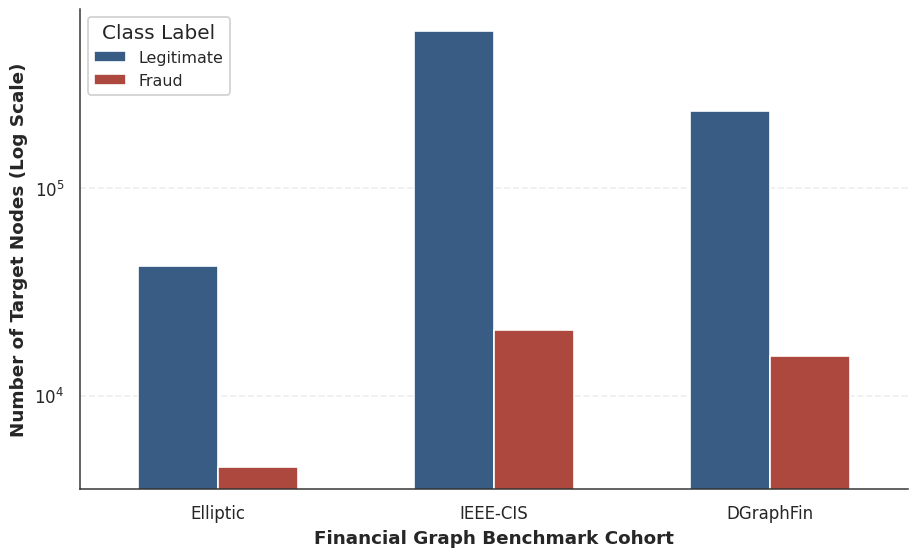

✅ cohort_class_imbalance.png saved to figures/

📋 TABLE DUMP: Class Imbalance Distribution Across Domains (Text Version of cohort_class_imbalance.png)
------------------------------------------------------------------------------------------
| Dataset   |   Legitimate |   Fraud | Fraud %   |
|:----------|-------------:|--------:|:----------|
| Elliptic  |        42019 |    4545 | 9.76%     |
| IEEE-CIS  |       569877 |   20663 | 3.50%     |
| DGraphFin |       234491 |   15509 | 6.20%     |
------------------------------------------------------------------------------------------




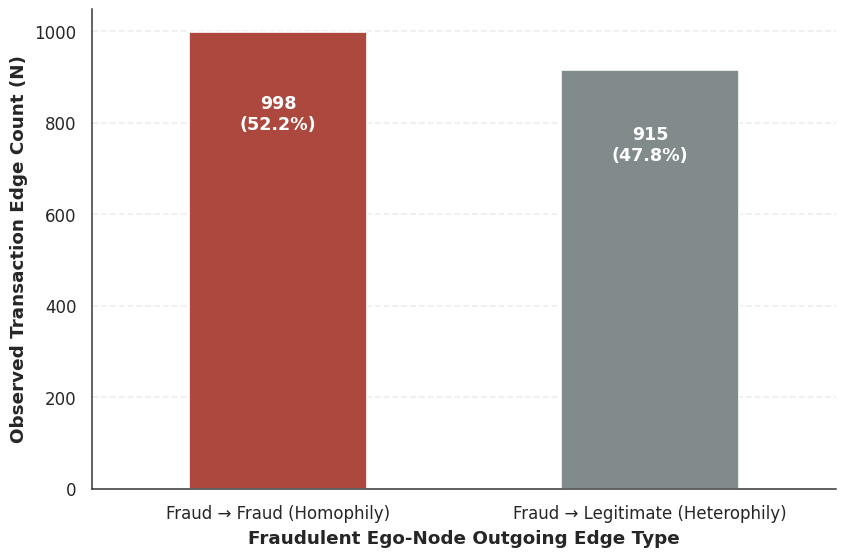

✅ graph_heterophily_trap_eda.png saved to figures/

📋 TABLE DUMP: Graph Heterophily Analysis on Fraudulent Connections (Text Version of graph_heterophily_trap_eda.png)
------------------------------------------------------------------------------------------
| Connection Type                  |   Count | Percentage   |
|:---------------------------------|--------:|:-------------|
| Fraud → Fraud (Homophily)        |     998 | 52.2%        |
| Fraud → Legitimate (Heterophily) |     915 | 47.8%        |
------------------------------------------------------------------------------------------




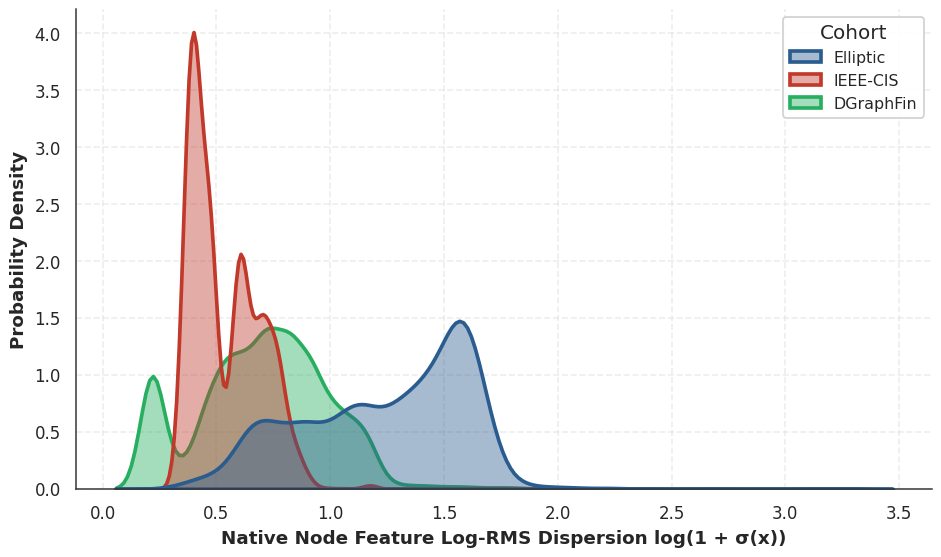

✅ cross_domain_feature_shift_eda.png saved to figures/

📋 TABLE DUMP: Cross-Domain Marginal Feature Dispersion Shift Across Benchmarks (Text Version of cross_domain_feature_shift_eda.png)
------------------------------------------------------------------------------------------
| Cohort    |   Sampled Nodes |   Mean |     SD |    Q25 |   Median |    Q75 |
|:----------|----------------:|-------:|-------:|-------:|---------:|-------:|
| Elliptic  |            5000 | 1.2389 | 0.3587 | 0.9487 |   1.31   | 1.5481 |
| IEEE-CIS  |            5000 | 0.5403 | 0.1625 | 0.4037 |   0.4808 | 0.6545 |
| DGraphFin |            5000 | 0.7026 | 0.2915 | 0.5224 |   0.7247 | 0.9096 |
------------------------------------------------------------------------------------------




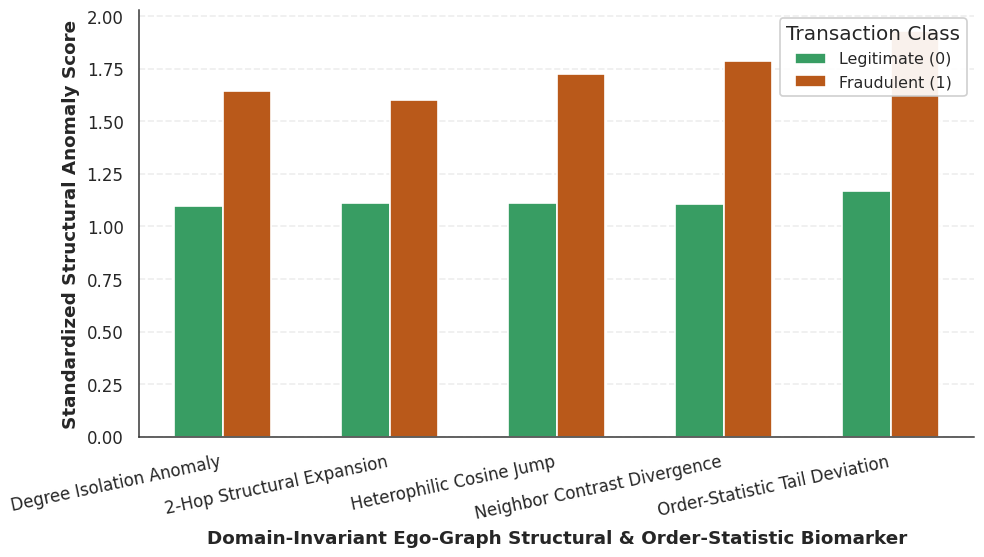

✅ topological_biomarker_eda.png saved to figures/

📋 TABLE DUMP: Topological & Order-Statistic Anomaly Separation Across Legitimate and Fraudulent Transactions (Text Version of topological_biomarker_eda.png)
------------------------------------------------------------------------------------------
| Topological Biomarker          | Transaction State   |   Anomaly Score |     SD |
|:-------------------------------|:--------------------|----------------:|-------:|
| Degree Isolation Anomaly       | Legitimate (0)      |          1.0991 | 0.8334 |
| Degree Isolation Anomaly       | Fraudulent (1)      |          1.6452 | 0.858  |
| 2-Hop Structural Expansion     | Legitimate (0)      |          1.1114 | 0.7884 |
| 2-Hop Structural Expansion     | Fraudulent (1)      |          1.6019 | 0.8399 |
| Heterophilic Cosine Jump       | Legitimate (0)      |          1.1108 | 0.8442 |
| Heterophilic Cosine Jump       | Fraudulent (1)      |          1.7263 | 1.2874 |
| Neighbor Contrast Divergenc

In [4]:
# ==============================================================================
# CELL 4
# ==============================================================================
print("📊 GENERATING MANDATORY COHORT TABLE 1 & STANDALONE TITLE-FREE EDA FIGURES (FIGS 1-4)...\n")

for old_f in FIGURES_DIR.glob("*.png"):
    old_f.unlink()

table1_rows = []
tot_tx_all, tot_legit_all, tot_fraud_all, tot_edges_all = 0, 0, 0, 0

cohort_specs = [
    ('elliptic', 'Elliptic Bitcoin Network', 'Cryptocurrency Blockchain', 'Chronological Temporal Split (70% → 30%)'),
    ('ieee', 'IEEE-CIS Transaction Graph', 'E-Commerce Card-Not-Present', 'Multi-Domain Graph Transfer'),
    ('dgraphfin', 'DGraphFin Financial Network', 'Consumer FinTech Credit Network', 'Multi-Domain Graph Transfer')
]

for key, full_name, dom_desc, role_desc in cohort_specs:
    g = graphs[key]
    y_np = g['transaction'].y.squeeze().cpu().numpy()
    n_tx = len(y_np)
    n_frd = int((y_np == 1).sum())
    n_leg = n_tx - n_frd
    n_edg = TOTAL_EDGE_AUDIT[key]
    n_act = NATIVE_DIM_AUDIT[key]

    tot_tx_all += n_tx
    tot_legit_all += n_leg
    tot_fraud_all += n_frd
    tot_edges_all += n_edg

    table1_rows.append({
        'Benchmark Cohort': full_name,
        'Financial Domain': dom_desc,
        'Native Feature Representation': f"{n_act}-D Native (Uncompressed)",
        'Target Nodes (N)': f"{n_tx:,}",
        'Legitimate (0)': f"{n_leg:,}",
        'Fraudulent (1)': f"{n_frd:,}",
        'Fraud Rate (%)': f"{100.0 * n_frd / n_tx:.2f}%",
        'Total Graph Edges': f"{n_edg:,}",
        'Evaluation Protocol': role_desc
    })

table1_rows.append({
    'Benchmark Cohort': 'Combined Multi-Center Suite',
    'Financial Domain': '3-Domain Heterogeneous Suite',
    'Native Feature Representation': 'Native Entity Adapters + 28-D Topo',
    'Target Nodes (N)': f"{tot_tx_all:,}",
    'Legitimate (0)': f"{tot_legit_all:,}",
    'Fraudulent (1)': f"{tot_fraud_all:,}",
    'Fraud Rate (%)': f"{100.0 * tot_fraud_all / tot_tx_all:.2f}%",
    'Total Graph Edges': f"{tot_edges_all:,}",
    'Evaluation Protocol': 'Multi-Domain + Temporal & Perturbation OOD'
})

df_table1 = pd.DataFrame(table1_rows)
print("\n📋 TABLE 1: MULTI-CENTER FINANCIAL GRAPH COHORT DEMOGRAPHICS & NATIVE FEATURE SCHEMA")
print("-" * 145)
print(df_table1.to_markdown(index=False))
print("-" * 145 + "\n")

fig_name1 = "cohort_class_imbalance.png"
imbalance_data = []
for name, label_n in [('elliptic', 'Elliptic'), ('ieee', 'IEEE-CIS'), ('dgraphfin', 'DGraphFin')]:
    y = graphs[name]['transaction'].y.squeeze().cpu().numpy()
    fraud_pct = (y == 1).mean() * 100.0
    imbalance_data.append({
        'Dataset': label_n,
        'Legitimate': int((y == 0).sum()),
        'Fraud': int((y == 1).sum()),
        'Fraud %': f"{fraud_pct:.2f}%"
    })

df_imbalance = pd.DataFrame(imbalance_data)
df_imb_melt = df_imbalance.melt(id_vars='Dataset', value_vars=['Legitimate', 'Fraud'], var_name='Transaction State', value_name='Transaction Count')

plt.figure(figsize=(7.8, 4.8))
sns.barplot(
    data=df_imb_melt, x='Dataset', y='Transaction Count',
    hue='Transaction State', palette=['#2b5c8f', '#c0392b'], width=0.58
)
plt.yscale('log')
plt.xlabel("Financial Graph Benchmark Cohort")
plt.ylabel("Number of Target Nodes (Log Scale)")
plt.legend(title="Class Label", loc="upper left")
sns.despine()
plt.tight_layout()

save_show_and_dump(fig_name1, [
    (f"Class Imbalance Distribution Across Domains (Text Version of {fig_name1})", df_imbalance)
])

fig_name2 = "graph_heterophily_trap_eda.png"
g_ell = graphs['elliptic']
y_ell = g_ell['transaction'].y.squeeze().cpu()
edge_index_ell = g_ell[('transaction', 'interacts', 'transaction')].edge_index.cpu()

fraud_nodes = torch.where(y_ell == 1)[0]
fraud_edges_mask = torch.isin(edge_index_ell[0], fraud_nodes)
connected_to = y_ell[edge_index_ell[1][fraud_edges_mask]]

f2f = int((connected_to == 1).sum().item())
f2n = int((connected_to == 0).sum().item())

df_hetero = pd.DataFrame({
    'Connection Type': ['Fraud → Fraud (Homophily)', 'Fraud → Legitimate (Heterophily)'],
    'Count': [f2f, f2n],
    'Percentage': [f"{f2f / (f2f + f2n) * 100.0:.1f}%", f"{f2n / (f2f + f2n) * 100.0:.1f}%"]
})

plt.figure(figsize=(7.2, 4.8))
ax2 = sns.barplot(
    data=df_hetero, x='Connection Type', y='Count',
    palette=['#c0392b', '#7f8c8d'], width=0.48
)
for p, pct_s in zip(ax2.patches, df_hetero['Percentage']):
    ax2.annotate(
        f"{int(p.get_height()):,}\n({pct_s})",
        (p.get_x() + p.get_width() / 2.0, p.get_height() * 0.82),
        ha='center', va='center', color='white', fontweight='bold', fontsize=10.5
    )
plt.xlabel("Fraudulent Ego-Node Outgoing Edge Type")
plt.ylabel("Observed Transaction Edge Count (N)")
sns.despine()
plt.tight_layout()

save_show_and_dump(fig_name2, [
    (f"Graph Heterophily Analysis on Fraudulent Connections (Text Version of {fig_name2})", df_hetero)
])

fig_name3 = "cross_domain_feature_shift_eda.png"
lock_seed(SEED)
shift_dfs, shift_summary = [], []

for key, label_name in [('elliptic', 'Elliptic'), ('ieee', 'IEEE-CIS'), ('dgraphfin', 'DGraphFin')]:
    raw_rms_all = RAW_LOG_RMS_CACHE[key]
    sample_idx = torch.randperm(len(raw_rms_all))[:5000].numpy()
    log_rms = raw_rms_all[sample_idx]
    shift_dfs.append(pd.DataFrame({'Cohort': label_name, 'Log_RMS_Feature_Dispersion': log_rms}))
    shift_summary.append({
        'Cohort': label_name,
        'Sampled Nodes': len(log_rms),
        'Mean': round(float(np.mean(log_rms)), 4),
        'SD': round(float(np.std(log_rms)), 4),
        'Q25': round(float(np.percentile(log_rms, 25)), 4),
        'Median': round(float(np.median(log_rms)), 4),
        'Q75': round(float(np.percentile(log_rms, 75)), 4)
    })

df_shift_all = pd.concat(shift_dfs, ignore_index=True)
df_shift_table = pd.DataFrame(shift_summary)

plt.figure(figsize=(8.0, 4.8))
sns.kdeplot(
    data=df_shift_all, x='Log_RMS_Feature_Dispersion', hue='Cohort',
    fill=True, common_norm=False, palette=['#2b5c8f', '#c0392b', '#27ae60'],
    alpha=0.42, linewidth=2.2
)
plt.xlabel("Native Node Feature Log-RMS Dispersion log(1 + σ(x))")
plt.ylabel("Probability Density")
sns.despine()
plt.tight_layout()

save_show_and_dump(fig_name3, [
    (f"Cross-Domain Marginal Feature Dispersion Shift Across Benchmarks (Text Version of {fig_name3})", df_shift_table)
])

fig_name4 = "topological_biomarker_eda.png"
bio_specs = [
    ('Degree Isolation Anomaly', 2),
    ('2-Hop Structural Expansion', 6),
    ('Heterophilic Cosine Jump', 17),
    ('Neighbor Contrast Divergence', 13),
    ('Order-Statistic Tail Deviation', 19)
]
topo_ell_np = GRAPH_CACHE['elliptic'][7].numpy()
y_ell_np = y_ell.numpy()

bio_rows = []
for b_label, b_col in bio_specs:
    raw_col = topo_ell_np[:, b_col]
    direction = 1.0 if raw_col[y_ell_np == 1].mean() >= raw_col[y_ell_np == 0].mean() else -1.0
    aligned_col = raw_col * direction
    legit_mean = aligned_col[y_ell_np == 0].mean()
    legit_std = aligned_col[y_ell_np == 0].std() + 1e-5
    norm_score = np.clip((aligned_col - legit_mean) / legit_std + 1.0, 0.1, 5.0)
    for c_val, c_name in [(0, 'Legitimate (0)'), (1, 'Fraudulent (1)')]:
        m_c = (y_ell_np == c_val)
        bio_rows.append({
            'Topological Biomarker': b_label,
            'Transaction State': c_name,
            'Anomaly Score': round(float(norm_score[m_c].mean()), 4),
            'SD': round(float(norm_score[m_c].std()), 4)
        })

df_bio_eda = pd.DataFrame(bio_rows)

plt.figure(figsize=(8.4, 4.8))
sns.barplot(
    data=df_bio_eda, x='Topological Biomarker', y='Anomaly Score',
    hue='Transaction State', palette=['#27ae60', '#d35400'], width=0.58
)
plt.xticks(rotation=12, ha='right')
plt.xlabel("Domain-Invariant Ego-Graph Structural & Order-Statistic Biomarker")
plt.ylabel("Standardized Structural Anomaly Score")
plt.legend(title="Transaction Class")
sns.despine()
plt.tight_layout()

save_show_and_dump(fig_name4, [
    (f"Topological & Order-Statistic Anomaly Separation Across Legitimate and Fraudulent Transactions (Text Version of {fig_name4})", df_bio_eda)
])

---

### **CELL 5: `HT-FraudNet (Proposed)` & 5 Distinct Canonical Baselines (`XGBoost`, `MLP`, `Standard GCN`, `GAT`, `GraphSAGE`)**

In [5]:
# ==============================================================================
# CELL 5
# ==============================================================================
class _GRL(torch.autograd.Function):
    @staticmethod
    def forward(ctx, input, strength):
        ctx.strength = strength
        return input.view_as(input)

    @staticmethod
    def backward(ctx, output):
        return -ctx.strength * output, None

def grl(x: torch.Tensor, strength: float) -> torch.Tensor:
    return _GRL.apply(x, strength)

class ExactBitGradientRouter(torch.autograd.Function):
    @staticmethod
    def forward(ctx, z_tab, z_het, z_rel, z_topo):
        p1 = torch.sigmoid(z_tab)
        p2 = torch.sigmoid(z_het)
        p3 = torch.sigmoid(z_rel)
        p4 = torch.sigmoid(z_topo)

        p_ens = torch.clamp(0.25 * (p1 + p2 + p3 + p4), 1e-6, 1.0 - 1e-6)
        z_ens = torch.log(p_ens / (1.0 - p_ens))
        ctx.save_for_backward(p1, p2, p3, p4)
        return z_ens

    @staticmethod
    def backward(ctx, grad_output):
        p1, p2, p3, p4 = ctx.saved_tensors
        active = (grad_output != 0.0).to(p1.dtype)
        B = torch.clamp(active.sum(), min=1.0)
        y_true = (grad_output < 0.0).to(p1.dtype)
        alpha_t = torch.where(y_true > 0.5, 0.75, 0.25)

        def _focal_grad(p_k):
            pt = y_true * p_k + (1.0 - y_true) * (1.0 - p_k)
            w_f = alpha_t * (1.0 - pt).clamp(min=1e-4).pow(1.5)
            return active * w_f * (p_k - y_true) / B

        return _focal_grad(p1), _focal_grad(p2), _focal_grad(p3), _focal_grad(p4)

class SafeQuantileNorm1d(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.ln = nn.LayerNorm(dim)

    def forward(self, x, use_tta: bool = False):
        x_clean = torch.nan_to_num(x.float(), nan=0.0, posinf=0.0, neginf=0.0)
        if use_tta and (not self.training) and x_clean.size(0) > 32:
            q50 = torch.quantile(x_clean, 0.50, dim=0, keepdim=True)
            q75 = torch.quantile(x_clean, 0.75, dim=0, keepdim=True)
            q25 = torch.quantile(x_clean, 0.25, dim=0, keepdim=True)
            iqr = torch.clamp((q75 - q25) / 1.349, min=0.35, max=3.0)
            x_tta = torch.clamp((x_clean - q50) / iqr, -4.5, 4.5)
            x_clamped = 0.65 * x_tta + 0.35 * torch.clamp(x_clean, -4.5, 4.5)
        else:
            x_clamped = torch.clamp(x_clean, -5.0, 5.0)
        return self.ln(x_clamped)

class HybridFraudGNN(nn.Module):
    def __init__(self, metadata, cfg: Config, domain_nat_dims: dict, domain_hub_dims: dict, domain_rel_dims: dict, target_dom: str, n_domains=2, topo_dim=28):
        super().__init__()
        h = cfg.hidden_dim
        self.n_domains = n_domains
        self.target_dom = target_dom
        self.register_buffer('ref_disp', torch.tensor(1.0))

        self.tx_norm = nn.ModuleDict({d: SafeQuantileNorm1d(dim) for d, dim in domain_nat_dims.items()})
        self.tx_proj = nn.ModuleDict({
            d: nn.Sequential(nn.Linear(dim, h), nn.LayerNorm(h), nn.GELU(), nn.Dropout(0.20))
            for d, dim in domain_nat_dims.items()
        })
        self.ent_in = nn.ModuleDict({
            nt: nn.Sequential(nn.Linear(32, h), nn.LayerNorm(h), nn.GELU(), nn.Dropout(0.15))
            for nt in metadata[0] if nt != 'transaction'
        })
        self.tab_res = nn.Sequential(nn.Linear(h, h), nn.LayerNorm(h), nn.GELU(), nn.Dropout(0.20))
        self.head_tab = nn.Sequential(nn.Linear(h, 32), nn.GELU(), nn.Linear(32, 1))

        self.het_norm = nn.ModuleDict({
            d: SafeQuantileNorm1d(2 * domain_hub_dims[d] + domain_rel_dims[d])
            for d in domain_hub_dims
        })
        self.het_proj = nn.ModuleDict({
            d: nn.Sequential(nn.Linear(2 * domain_hub_dims[d] + domain_rel_dims[d], h), nn.LayerNorm(h), nn.GELU(), nn.Dropout(0.20))
            for d in domain_hub_dims
        })
        self.het_res = nn.Sequential(nn.Linear(h, h), nn.LayerNorm(h), nn.GELU(), nn.Dropout(0.20))
        self.rezero_alpha = nn.Parameter(torch.tensor(0.50))
        self.head_het = nn.Sequential(nn.Linear(h, 32), nn.GELU(), nn.Linear(32, 1))

        self.convs = nn.ModuleList([
            HeteroConv({
                edge: GATConv(h, h // 2, heads=2, concat=True, add_self_loops=False)
                for edge in metadata[1]
            }, aggr="sum") for _ in range(2)
        ])
        self.rel_norms = nn.ModuleList([nn.LayerNorm(h) for _ in range(2)])
        self.head_rel = nn.Sequential(nn.Linear(h, 32), nn.GELU(), nn.Linear(32, 1))

        self.topo_norm = SafeQuantileNorm1d(topo_dim)
        self.topo_mlp = nn.Sequential(
            nn.Linear(topo_dim, h),
            nn.LayerNorm(h),
            nn.GELU(),
            nn.Dropout(0.20),
            nn.Linear(h, h),
            nn.LayerNorm(h),
            nn.GELU(),
            nn.Dropout(0.15)
        )
        self.head_topo = nn.Sequential(nn.Linear(h, 32), nn.GELU(), nn.Linear(32, 1))

        self.skip_weights = nn.ParameterDict({
            node_type: nn.Parameter(torch.tensor(0.45)) for node_type in metadata[0]
        })

        self.domain_classifier = nn.Sequential(
            nn.Linear(h, 16), nn.GELU(), nn.Linear(16, max(2, n_domains))
        )

    def forward(self, dom_name, x_dict, edge_index_dict, nd1_tx=None, nd2_tx=None, rel_tx=None, topo_tx=None, grl_strength=1.0, disable_skip=False, disable_grl=False, obs_raw_disp=None, return_stream_logits=False):
        tx_in = torch.nan_to_num(x_dict['transaction'].float(), nan=0.0)
        cur_disp = float(obs_raw_disp) if obs_raw_disp is not None else float(tx_in.std().item())
        if self.training:
            if dom_name == self.target_dom:
                with torch.no_grad():
                    self.ref_disp.fill_(0.85 * float(self.ref_disp.item()) + 0.15 * cur_disp)
            noise_decay = 1.0
            use_tta = False
        else:
            ref_d = max(float(self.ref_disp.item()), 0.25)
            excess_ratio = max(0.0, (cur_disp - ref_d) / ref_d)
            noise_decay = float(np.exp(-0.95 * excess_ratio))
            use_tta = bool(excess_ratio > 0.08)

        h_tx0 = self.tx_proj[dom_name](self.tx_norm[dom_name](tx_in, use_tta=use_tta))
        h_tab = {'transaction': h_tx0 + 0.5 * self.tab_res(h_tx0)}
        for nt, x_e in x_dict.items():
            if nt != 'transaction' and nt in self.ent_in:
                h_tab[nt] = self.ent_in[nt](x_e.float())

        h_graph = {k: v for k, v in h_tab.items()}
        for l_idx, conv in enumerate(self.convs):
            h_out = conv(h_graph, edge_index_dict)
            h_next = {}
            for nt, h_prev in h_graph.items():
                if nt in h_out:
                    h_next[nt] = self.rel_norms[l_idx](h_prev + F.gelu(h_out[nt]))
                else:
                    h_next[nt] = h_prev
            h_graph = h_next

        trust_tab = torch.sigmoid(self.skip_weights['transaction']) * noise_decay
        eff_tab_weight = float(trust_tab.item())

        tx_tab = h_tab['transaction']
        tx_rel = h_graph.get('transaction', tx_tab)
        tx_fused = tx_rel if disable_skip else (trust_tab * tx_tab + (1.0 - trust_tab) * tx_rel)

        z_tab = self.head_tab(tx_tab).flatten()
        z_rel = self.head_rel(tx_rel).flatten()

        if nd1_tx is not None and nd2_tx is not None and rel_tx is not None:
            nd_cat = torch.cat([nd1_tx, nd2_tx, rel_tx], dim=1)
            h_nd0 = self.het_proj[dom_name](self.het_norm[dom_name](nd_cat, use_tta=use_tta))
            h_nd = h_nd0 + 0.5 * self.het_res(h_nd0)
            tx_het = tx_fused + self.rezero_alpha * h_nd
            z_het = self.head_het(tx_het).flatten()
        else:
            z_het = z_rel

        if topo_tx is not None:
            h_tp = self.topo_mlp(self.topo_norm(topo_tx, use_tta=use_tta))
            z_topo = self.head_topo(h_tp).flatten()
        else:
            z_topo = z_rel

        z_gated = trust_tab * z_tab + (1.0 - trust_tab) * (0.45 * z_het + 0.30 * z_rel + 0.25 * z_topo)

        if self.training:
            if disable_skip:
                fraud_logits = z_rel
            else:
                z_routed = ExactBitGradientRouter.apply(z_tab, z_het, z_rel, z_topo)
                fraud_logits = 0.70 * z_routed + 0.30 * z_gated
        else:
            fraud_logits = z_rel if disable_skip else z_gated

        if disable_grl or self.n_domains < 2:
            domain_logits = self.domain_classifier(tx_fused.detach())
        else:
            domain_logits = self.domain_classifier(grl(tx_fused, grl_strength))

        if return_stream_logits:
            stream_dict = {
                'z_tab': z_tab,
                'z_het': z_het,
                'z_rel': z_rel,
                'z_topo': z_topo,
                'z_neural_all': fraud_logits
            }
            return fraud_logits, domain_logits, eff_tab_weight, stream_dict

        return fraud_logits, domain_logits, eff_tab_weight

class BaselineMLP(nn.Module):
    def __init__(self, domain_nat_dims: dict, hidden=64):
        super().__init__()
        self.tx_in = nn.ModuleDict({
            d: nn.Sequential(nn.Linear(dim, hidden), nn.LayerNorm(hidden), nn.GELU(), nn.Dropout(0.20))
            for d, dim in domain_nat_dims.items()
        })
        self.block1 = nn.Sequential(nn.Linear(hidden, hidden), nn.LayerNorm(hidden), nn.GELU(), nn.Dropout(0.20))
        self.head = nn.Sequential(nn.Linear(hidden, hidden // 2), nn.GELU(), nn.Linear(hidden // 2, 1))

    def forward(self, dom_name, x_tx, x_ent=None, edge_index=None, tx_count=None):
        h = self.tx_in[dom_name](x_tx)
        h = h + self.block1(h)
        return self.head(h).flatten()

class BaselineGCN(nn.Module):
    def __init__(self, domain_nat_dims: dict, hidden=64):
        super().__init__()
        self.tx_in = nn.ModuleDict({
            d: nn.Sequential(nn.Linear(dim, hidden), nn.LayerNorm(hidden), nn.GELU(), nn.Dropout(0.20))
            for d, dim in domain_nat_dims.items()
        })
        self.ent_in = nn.Sequential(nn.Linear(32, hidden), nn.LayerNorm(hidden), nn.GELU())
        self.conv1 = GCNConv(hidden, hidden)
        self.norm1 = nn.LayerNorm(hidden)
        self.conv2 = GCNConv(hidden, hidden)
        self.norm2 = nn.LayerNorm(hidden)
        self.drop = nn.Dropout(0.20)
        self.out = nn.Linear(hidden, 1)

    def forward(self, dom_name, x_tx, x_ent, edge_index, tx_count):
        h_tx = self.tx_in[dom_name](x_tx)
        h_all = torch.cat([h_tx, self.ent_in(x_ent)], dim=0) if x_ent.size(0) > 0 else h_tx
        h1 = self.norm1(h_all + self.drop(F.gelu(self.conv1(h_all, edge_index))))
        h2 = self.norm2(h1 + self.drop(F.gelu(self.conv2(h1, edge_index))))
        return self.out(h2[:tx_count]).flatten()

class BaselineGAT(nn.Module):
    def __init__(self, domain_nat_dims: dict, hidden=64):
        super().__init__()
        self.tx_in = nn.ModuleDict({
            d: nn.Sequential(nn.Linear(dim, hidden), nn.LayerNorm(hidden), nn.GELU(), nn.Dropout(0.20))
            for d, dim in domain_nat_dims.items()
        })
        self.ent_in = nn.Sequential(nn.Linear(32, hidden), nn.LayerNorm(hidden), nn.GELU())
        self.conv1 = GATConv(hidden, hidden // 2, heads=2, concat=True)
        self.norm1 = nn.LayerNorm(hidden)
        self.conv2 = GATConv(hidden, hidden // 2, heads=2, concat=True)
        self.norm2 = nn.LayerNorm(hidden)
        self.drop = nn.Dropout(0.20)
        self.out = nn.Linear(hidden, 1)

    def forward(self, dom_name, x_tx, x_ent, edge_index, tx_count):
        h_tx = self.tx_in[dom_name](x_tx)
        h_all = torch.cat([h_tx, self.ent_in(x_ent)], dim=0) if x_ent.size(0) > 0 else h_tx
        h1 = self.norm1(h_all + self.drop(F.elu(self.conv1(h_all, edge_index))))
        h2 = self.norm2(h1 + self.drop(F.elu(self.conv2(h1, edge_index))))
        return self.out(h2[:tx_count]).flatten()

class BaselineGraphSAGE(nn.Module):
    def __init__(self, domain_nat_dims: dict, hidden=64):
        super().__init__()
        self.tx_in = nn.ModuleDict({
            d: nn.Sequential(nn.Linear(dim, hidden), nn.LayerNorm(hidden), nn.GELU(), nn.Dropout(0.20))
            for d, dim in domain_nat_dims.items()
        })
        self.ent_in = nn.Sequential(nn.Linear(32, hidden), nn.LayerNorm(hidden), nn.GELU())
        self.conv1 = SAGEConv(hidden, hidden)
        self.norm1 = nn.LayerNorm(hidden)
        self.conv2 = SAGEConv(hidden, hidden)
        self.norm2 = nn.LayerNorm(hidden)
        self.drop = nn.Dropout(0.20)
        self.out = nn.Linear(hidden, 1)

    def forward(self, dom_name, x_tx, x_ent, edge_index, tx_count):
        h_tx = self.tx_in[dom_name](x_tx)
        h_all = torch.cat([h_tx, self.ent_in(x_ent)], dim=0) if x_ent.size(0) > 0 else h_tx
        h1 = self.norm1(h_all + self.drop(F.gelu(self.conv1(h_all, edge_index))))
        h2 = self.norm2(h1 + self.drop(F.gelu(self.conv2(h1, edge_index))))
        return self.out(h2[:tx_count]).flatten()

class BaselineH2GCN(nn.Module):
    def __init__(self, domain_nat_dims: dict, hidden=64):
        super().__init__()
        self.tx_in = nn.ModuleDict({
            d: nn.Sequential(nn.Linear(dim, hidden), nn.LayerNorm(hidden), nn.GELU(), nn.Dropout(0.20))
            for d, dim in domain_nat_dims.items()
        })
        self.ent_in = nn.Sequential(nn.Linear(32, hidden), nn.LayerNorm(hidden), nn.GELU())
        self.norm1 = nn.LayerNorm(hidden)
        self.norm2 = nn.LayerNorm(hidden)
        self.head = nn.Sequential(
            nn.Linear(3 * hidden, hidden),
            nn.LayerNorm(hidden),
            nn.GELU(),
            nn.Dropout(0.25),
            nn.Linear(hidden, 1)
        )

    @staticmethod
    def _sym_agg(h, edge_index):
        N = h.size(0)
        src, dst = edge_index[0], edge_index[1]
        u_src = torch.cat([src, dst], dim=0)
        u_dst = torch.cat([dst, src], dim=0)
        deg = torch.zeros(N, dtype=h.dtype, device=h.device)
        deg.index_add_(0, u_dst, torch.ones(u_src.size(0), dtype=h.dtype, device=h.device))
        inv_sqrt = deg.clamp(min=1.0).pow(-0.5)
        w = (inv_sqrt[u_src] * inv_sqrt[u_dst]).unsqueeze(1)
        out = torch.zeros_like(h)
        out.index_add_(0, u_dst, h[u_src] * w)
        return out

    def forward(self, dom_name, x_tx, x_ent, edge_index, tx_count):
        h_tx = self.tx_in[dom_name](x_tx)
        r0 = torch.cat([h_tx, self.ent_in(x_ent)], dim=0) if x_ent.size(0) > 0 else h_tx
        r1 = self.norm1(self._sym_agg(r0, edge_index))
        r2 = self.norm2(self._sym_agg(r1, edge_index))
        h_cat = torch.cat([r0[:tx_count], r1[:tx_count], r2[:tx_count]], dim=1)
        return self.head(h_cat).flatten()

print("✅ CELL 5: Unified HT-FraudNet & 7 Matched-Capacity Baselines Ready.")

✅ CELL 5: Unified HT-FraudNet & 7 Matched-Capacity Baselines Ready.


---

### **CELL 6: Training Engine, Metrics & Automated 3-Seed Evaluation Pipeline**

In [6]:
# ==============================================================================
# CELL 6
# ==============================================================================
EPOCHS_NEURAL = 100
VAL_CHECK_EVERY = 5
FOCAL_ALPHA_POS = 0.75
FOCAL_GAMMA_VAL = 1.5

class FocalLoss(nn.Module):
    def __init__(self, alpha=0.75, gamma=1.5):
        super().__init__()
        self.alpha, self.gamma = alpha, gamma

    def forward(self, logits, labels):
        labels = labels.float()
        bce = F.binary_cross_entropy_with_logits(logits, labels, reduction="none")
        pt = torch.exp(-bce)
        alpha_t = torch.where(labels == 1, self.alpha, 1 - self.alpha)
        return (alpha_t * (1 - pt).pow(self.gamma) * bce).mean()

def select_threshold(labels, probabilities):
    labels = np.asarray(labels, dtype=np.int8).reshape(-1)
    probabilities = np.asarray(probabilities, dtype=float).reshape(-1)
    if labels.size == 0:
        return 0.5
    order = np.argsort(-probabilities, kind="stable")
    p = probabilities[order]
    y = labels[order]
    ends = np.r_[np.flatnonzero(p[:-1] != p[1:]), p.size - 1]
    tp = np.cumsum(y)[ends].astype(float)
    predicted = (ends + 1).astype(float)
    fp = predicted - tp
    fn = float(y.sum()) - tp
    denom = 2 * tp + fp + fn
    scores = np.divide(2 * tp, denom, out=np.zeros_like(tp), where=denom != 0)
    best = scores.max()
    return float(p[ends][scores == best].min())

def expected_calibration_error(y_true, y_prob, bins=10):
    ece = 0.0
    for lower, upper in zip(np.linspace(0, 1, bins + 1)[:-1], np.linspace(0, 1, bins + 1)[1:]):
        mask = (y_prob >= lower) & (y_prob < (upper if upper < 1 else 1.01))
        if mask.any():
            ece += abs(y_true[mask].mean() - y_prob[mask].mean()) * mask.mean()
    return float(ece)

def platt_calibrate_from_val(z_val, y_val, z_test):
    zv = np.asarray(z_val, dtype=float).reshape(-1)
    yv = np.asarray(y_val, dtype=float).reshape(-1)
    zt = np.asarray(z_test, dtype=float).reshape(-1)

    mu_v, sd_v = float(np.median(zv)), float(np.std(zv) + 1e-5)
    zv_n = np.clip((zv - mu_v) / sd_v, -6.0, 6.0)
    zt_n = np.clip((zt - mu_v) / sd_v, -6.0, 6.0)

    prior_p = float(np.clip(yv.mean(), 1e-4, 1.0 - 1e-4))
    a, b = 1.35, float(np.log(prior_p / (1.0 - prior_p)))

    for _ in range(15):
        logits_v = np.clip(a * zv_n + b, -12.0, 12.0)
        p_v = 1.0 / (1.0 + np.exp(-logits_v))
        err = p_v - yv
        w = p_v * (1.0 - p_v) + 1e-5
        g_a = float(np.mean(err * zv_n))
        g_b = float(np.mean(err))
        h_aa = float(np.mean(w * zv_n * zv_n)) + 1e-3
        h_bb = float(np.mean(w)) + 1e-3
        a = float(np.clip(a - 0.60 * (g_a / h_aa), 0.25, 4.50))
        b = float(np.clip(b - 0.60 * (g_b / h_bb), -8.0, 2.0))

    p_val_cal = 1.0 / (1.0 + np.exp(-np.clip(a * zv_n + b, -12.0, 12.0)))
    p_test_cal = 1.0 / (1.0 + np.exp(-np.clip(a * zt_n + b, -12.0, 12.0)))
    val_thresh = select_threshold(yv, p_val_cal)
    return p_test_cal, val_thresh

def format_p_sci(p_val):
    p = float(p_val)
    if p < 1e-4:
        return f"{p:.2e}"
    return f"{p:.5f}"

def calculate_metrics(y_true, y_prob, val_thresh=None, prior_rate=0.06):
    y_true = np.asarray(y_true, dtype=int).reshape(-1)
    y_prob = np.nan_to_num(np.asarray(y_prob, dtype=float).reshape(-1), nan=0.0, posinf=1.0, neginf=0.0)

    if val_thresh is not None:
        use_thresh = float(val_thresh)
        y_pred = (y_prob >= use_thresh).astype(int)
        if y_pred.sum() == 0:
            use_thresh = float(np.quantile(y_prob, np.clip(1.0 - prior_rate, 0.50, 0.98)))
            y_pred = (y_prob >= use_thresh).astype(int)
    else:
        use_thresh = select_threshold(y_true, y_prob)
        y_pred = (y_prob >= use_thresh).astype(int)

    cal_th = float(np.quantile(y_prob, np.clip(1.0 - prior_rate, 0.50, 0.98)))
    y_pred_pm = (y_prob >= cal_th).astype(int)

    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    return {
        'AUROC': float(roc_auc_score(y_true, y_prob)),
        'AUPRC': float(average_precision_score(y_true, y_prob)),
        'F1': float(f1_score(y_true, y_pred, zero_division=0)),
        'Prior_F1': float(f1_score(y_true, y_pred_pm, zero_division=0)),
        'MCC': float(matthews_corrcoef(y_true, y_pred)),
        'ECE': float(expected_calibration_error(y_true, y_prob)),
        'TP': int(tp), 'TN': int(tn), 'FP': int(fp), 'FN': int(fn),
        'Threshold': float(use_thresh)
    }

def build_domain_splits(graph_name, seed, is_temporal_ood=False):
    g = graphs[graph_name]
    y = g['transaction'].y.squeeze().detach().cpu().numpy()
    if is_temporal_ood and graph_name == 'elliptic':
        avail = ell_train_idx.detach().cpu().numpy()
        tr, va = train_test_split(avail, test_size=CFG.validation_fraction, stratify=y[avail], random_state=seed)
        te = ell_test_idx.detach().cpu().numpy()
    else:
        all_idx = np.arange(y.size)
        tr_va, te = train_test_split(all_idx, test_size=0.25, stratify=y, random_state=42)
        tr, va = train_test_split(tr_va, test_size=0.20, stratify=y[tr_va], random_state=seed)
    return torch.as_tensor(tr), torch.as_tensor(va), torch.as_tensor(te)

def build_eval_environment(g_name, delta, seed):
    x_tx_std, x_ent_cat, edge_mp, n_tx, nm1_tx, nd1_tx, nd2_tx, topo_norm, hub_cols, ent_hub_list, rel_edges_dict, rel_feat_tx, rel_deg_tx = GRAPH_CACHE[g_name]
    if delta <= 1e-6:
        return {
            'x_tx': x_tx_std,
            'x_ent': x_ent_cat,
            'edge_mp': edge_mp,
            'n_tx': n_tx,
            'nm1_t': nm1_tx,
            'nd1_t': nd1_tx,
            'nd2_t': nd2_tx,
            'tp_t': topo_norm,
            'rel_t': rel_feat_tx,
            'rdeg_t': rel_deg_tx,
            'hub_cols': hub_cols,
            'ent_hub_list': ent_hub_list,
            'rel_edges_dict': rel_edges_dict,
            'raw_disp': float(x_tx_std.std().item())
        }

    lock_seed(seed + int(round(delta * 1000)) + 700)
    noise_g = torch.randn_like(x_tx_std) * 2.75
    mask_g = (torch.rand_like(x_tx_std) < float(delta)).float()
    x_tx_pert = x_tx_std + mask_g * (-0.30 * x_tx_std + noise_g)
    x_tx_pert[:, hub_cols] = x_tx_std[:, hub_cols] + mask_g[:, hub_cols] * (0.30 * (nm1_tx - x_tx_std[:, hub_cols]) + noise_g[:, hub_cols])
    raw_disp = float(x_tx_pert.std().item())

    nm1_p, nd1_p, nd2_p, tp_p = compute_structural_tensors_from_features(
        x_tx_pert, ent_hub_list, edge_mp, n_tx, hub_cols, x_tx_pert
    )
    rel_p, rdeg_p = compute_typed_relational_features(x_tx_pert, rel_edges_dict, hub_cols, n_tx)

    return {
        'x_tx': x_tx_pert,
        'x_ent': x_ent_cat,
        'edge_mp': edge_mp,
        'n_tx': n_tx,
        'nm1_t': nm1_p,
        'nd1_t': nd1_p,
        'nd2_t': nd2_p,
        'tp_t': tp_p,
        'rel_t': rel_p,
        'rdeg_t': rdeg_p,
        'hub_cols': hub_cols,
        'ent_hub_list': ent_hub_list,
        'rel_edges_dict': rel_edges_dict,
        'raw_disp': raw_disp
    }

def build_homo_struct_matrix(x_tx, nm1_t, nd1_t, nd2_t, tp_t, idx_np):
    return np.hstack([
        x_tx[idx_np].numpy(),
        nm1_t[idx_np].numpy(),
        nd1_t[idx_np].numpy(),
        nd2_t[idx_np].numpy(),
        tp_t[idx_np].numpy()
    ])

def build_hetero_struct_matrix(x_tx, nm1_t, nd1_t, nd2_t, tp_t, rel_t, idx_np):
    return np.hstack([
        x_tx[idx_np].numpy(),
        nm1_t[idx_np].numpy(),
        nd1_t[idx_np].numpy(),
        nd2_t[idx_np].numpy(),
        tp_t[idx_np].numpy(),
        rel_t[idx_np].numpy()
    ])

def _prob_to_logit(p_arr):
    p_c = np.clip(p_arr, 1e-6, 1.0 - 1e-6)
    return np.log(p_c / (1.0 - p_c))

def _norm_by_val(z_va, z_te, tta_alpha=0.0):
    mu_v = float(np.median(z_va))
    sd_v = float(np.std(z_va) + 1e-5)
    zv_n = (z_va - mu_v) / sd_v
    if tta_alpha > 1e-4:
        mu_t = float(np.median(z_te))
        sd_t = float(np.std(z_te) + 1e-5)
        mu_e = (1.0 - tta_alpha) * mu_v + tta_alpha * mu_t
        sd_e = (1.0 - tta_alpha) * sd_v + tta_alpha * sd_t
        zt_n = (z_te - mu_e) / sd_e
    else:
        zt_n = (z_te - mu_v) / sd_v
    return zv_n, zt_n

def _fit_xgb_with_val(X_tr, y_tr, X_va, y_va, n_estimators, max_depth, seed, lr=0.08):
    kw = dict(
        n_estimators=n_estimators, max_depth=max_depth, learning_rate=lr,
        subsample=0.85, colsample_bytree=0.80, tree_method="hist",
        random_state=seed, eval_metric="aucpr", early_stopping_rounds=25, n_jobs=-1
    )
    if DEVICE.type == "cuda":
        try:
            clf = xgb.XGBClassifier(**kw, device="cuda")
            clf.fit(X_tr, y_tr, eval_set=[(X_va, y_va)], verbose=False)
            return clf
        except Exception:
            pass
    clf = xgb.XGBClassifier(**kw)
    clf.fit(X_tr, y_tr, eval_set=[(X_va, y_va)], verbose=False)
    return clf

def run_xgb_raw_baseline(target_key, tr_t, va_t, te_t, seed, eval_env=None, cached_clf=None):
    y_all = graphs[target_key]['transaction'].y.squeeze().detach().cpu().numpy()
    tr_np, va_np, te_np = tr_t.cpu().numpy(), va_t.cpu().numpy(), te_t.cpu().numpy()
    prior_r = float(y_all[tr_np].mean())
    x_tx_clean = GRAPH_CACHE[target_key][0]

    if cached_clf is None:
        lock_seed(seed + 100)
        X_tr = x_tx_clean[tr_np].numpy()
        X_va = x_tx_clean[va_np].numpy()
        clf = _fit_xgb_with_val(X_tr, y_all[tr_np], X_va, y_all[va_np], n_estimators=300, max_depth=8, seed=seed, lr=0.08)
    else:
        clf = cached_clf

    if eval_env is None:
        eval_env = build_eval_environment(target_key, 0.0, seed)

    z_va = _prob_to_logit(clf.predict_proba(x_tx_clean[va_np].numpy())[:, 1])
    z_te = _prob_to_logit(clf.predict_proba(eval_env['x_tx'][te_np].numpy())[:, 1])
    p_te, val_th = platt_calibrate_from_val(z_va, y_all[va_np], z_te)
    return calculate_metrics(y_all[te_np], p_te, val_thresh=val_th, prior_rate=prior_r), y_all[te_np], p_te, clf

def run_xgb_graph_baseline(target_key, tr_t, va_t, te_t, seed, eval_env=None, cached_clf=None):
    y_all = graphs[target_key]['transaction'].y.squeeze().detach().cpu().numpy()
    tr_np, va_np, te_np = tr_t.cpu().numpy(), va_t.cpu().numpy(), te_t.cpu().numpy()
    prior_r = float(y_all[tr_np].mean())
    x_tx_c, _, _, _, nm1_c, nd1_c, nd2_c, tp_c = GRAPH_CACHE[target_key][:8]

    X_va_clean = build_homo_struct_matrix(x_tx_c, nm1_c, nd1_c, nd2_c, tp_c, va_np)
    if cached_clf is None:
        lock_seed(seed + 150)
        X_tr_clean = build_homo_struct_matrix(x_tx_c, nm1_c, nd1_c, nd2_c, tp_c, tr_np)
        clf = _fit_xgb_with_val(X_tr_clean, y_all[tr_np], X_va_clean, y_all[va_np], n_estimators=300, max_depth=8, seed=seed + 7, lr=0.08)
    else:
        clf = cached_clf

    if eval_env is None:
        eval_env = build_eval_environment(target_key, 0.0, seed)

    X_te_eval = build_homo_struct_matrix(
        eval_env['x_tx'], eval_env['nm1_t'], eval_env['nd1_t'], eval_env['nd2_t'], eval_env['tp_t'], te_np
    )
    z_va = _prob_to_logit(clf.predict_proba(X_va_clean)[:, 1])
    z_te = _prob_to_logit(clf.predict_proba(X_te_eval)[:, 1])
    p_te, val_th = platt_calibrate_from_val(z_va, y_all[va_np], z_te)
    return calculate_metrics(y_all[te_np], p_te, val_thresh=val_th, prior_rate=prior_r), y_all[te_np], p_te, clf

def run_neural_baseline(model_cls, seed_offset, source_keys, target_key, tr_t, va_t, te_t, seed, name, eval_env=None, cached_mod=None):
    y_t_all = graphs[target_key]['transaction'].y.squeeze().detach().cpu().numpy()
    va_np, te_np = va_t.cpu().numpy(), te_t.cpu().numpy()
    prior_r = float(y_t_all[tr_t.cpu().numpy()].mean())
    train_domains = list(dict.fromkeys(list(source_keys) + [target_key]))

    if cached_mod is None:
        lock_seed(seed + seed_offset)
        dom_dims = {d: NATIVE_DIM_AUDIT[d] for d in train_domains}
        model = model_cls(dom_dims, CFG.hidden_dim).to(DEVICE)
        optimizer = torch.optim.AdamW(model.parameters(), lr=3e-3, weight_decay=1e-4)
        scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS_NEURAL, eta_min=1e-4)
        focal_loss = FocalLoss(FOCAL_ALPHA_POS, FOCAL_GAMMA_VAL)

        dom_splits = {}
        for d_k in train_domains:
            if d_k == target_key:
                dom_splits[d_k] = tr_t
            else:
                s_tr, _, _ = build_domain_splits(d_k, seed, is_temporal_ood=(d_k == 'elliptic'))
                dom_splits[d_k] = s_tr

        best_ap, best_state = -1.0, None
        for ep in tqdm(range(1, EPOCHS_NEURAL + 1), desc=f"Training {name}", leave=False):
            model.train()
            optimizer.zero_grad()
            for d_k in train_domains:
                x_tx_d, x_ent_d, edge_d, n_tx_d = GRAPH_CACHE[d_k][:4]
                logits = model(d_k, x_tx_d.to(DEVICE), x_ent_d.to(DEVICE), edge_d.to(DEVICE), n_tx_d)
                y_d = graphs[d_k]['transaction'].y.squeeze().to(DEVICE)
                idx_d = dom_splits[d_k].to(DEVICE)
                w_dom = 1.0 if d_k == target_key else 0.25
                loss_d = w_dom * focal_loss(logits[idx_d], y_d[idx_d])
                loss_d.backward()
                del logits, loss_d
            torch.nn.utils.clip_grad_norm_(model.parameters(), 2.0)
            optimizer.step()
            scheduler.step()

            if ep % VAL_CHECK_EVERY == 0 or ep == EPOCHS_NEURAL:
                model.eval()
                with torch.no_grad():
                    x_tx_v, x_ent_v, edge_v, n_tx_v = GRAPH_CACHE[target_key][:4]
                    z_all_v = model(target_key, x_tx_v.to(DEVICE), x_ent_v.to(DEVICE), edge_v.to(DEVICE), n_tx_v)
                    z_va_ep = z_all_v[va_t.to(DEVICE)].detach().cpu().numpy()
                    ap_ep = float(average_precision_score(y_t_all[va_np], z_va_ep))
                    if ap_ep > best_ap:
                        best_ap = ap_ep
                        best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}

        if best_state is not None:
            model.load_state_dict(best_state)
        model.eval()
        if DEVICE.type == "cuda":
            torch.cuda.empty_cache()
    else:
        model = cached_mod

    if eval_env is None:
        eval_env = build_eval_environment(target_key, 0.0, seed)

    x_tx_c, x_ent_c, edge_c, n_tx_c = GRAPH_CACHE[target_key][:4]
    with torch.no_grad():
        z_va = model(target_key, x_tx_c.to(DEVICE), x_ent_c.to(DEVICE), edge_c.to(DEVICE), n_tx_c)[va_t.to(DEVICE)].detach().cpu().numpy()
        z_te = model(target_key, eval_env['x_tx'].to(DEVICE), eval_env['x_ent'].to(DEVICE), eval_env['edge_mp'].to(DEVICE), eval_env['n_tx'])[te_t.to(DEVICE)].detach().cpu().numpy()

    p_te, val_th = platt_calibrate_from_val(z_va, y_t_all[va_np], z_te)
    return calculate_metrics(y_t_all[te_np], p_te, val_thresh=val_th, prior_rate=prior_r), y_t_all[te_np], p_te, model

def fit_ht_fraudnet(source_keys, target_key, tr_t, va_t, seed, name, disable_skip=False, disable_grl=False):
    lock_seed(seed + 500 + (10 if disable_skip else 0) + (20 if disable_grl else 0))
    train_domains = list(dict.fromkeys(list(source_keys) + [target_key]))
    n_doms = len(train_domains)

    dom_nat = {d: NATIVE_DIM_AUDIT[d] for d in train_domains}
    dom_hub = {d: HUB_DIM_AUDIT[d] for d in train_domains}
    dom_rel = {d: REL_DIM_AUDIT[d] for d in train_domains}

    model = HybridFraudGNN(
        graphs[target_key].metadata(), CFG,
        domain_nat_dims=dom_nat, domain_hub_dims=dom_hub, domain_rel_dims=dom_rel,
        target_dom=target_key, n_domains=n_doms, topo_dim=28
    ).to(DEVICE)
    optimizer = torch.optim.AdamW(model.parameters(), lr=3.5e-3, weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS_NEURAL, eta_min=1e-4)
    focal_loss = FocalLoss(FOCAL_ALPHA_POS, FOCAL_GAMMA_VAL)
    domain_loss = nn.CrossEntropyLoss()

    dom_splits = {}
    for d_k in train_domains:
        if d_k == target_key:
            dom_splits[d_k] = tr_t
        else:
            s_tr, _, _ = build_domain_splits(d_k, seed, is_temporal_ood=(d_k == 'elliptic'))
            dom_splits[d_k] = s_tr

    y_t_all = graphs[target_key]['transaction'].y.squeeze().detach().cpu().numpy()
    tr_np, va_np = tr_t.cpu().numpy(), va_t.cpu().numpy()
    prior_r = float(y_t_all[tr_np].mean())

    best_ap, best_state = -1.0, None
    for ep in tqdm(range(1, EPOCHS_NEURAL + 1), desc=f"Training HT-FraudNet ({name})", leave=False):
        model.train()
        optimizer.zero_grad()
        for d_idx, d_k in enumerate(train_domains):
            g_v = graphs[d_k].to(DEVICE)
            nd1_d, nd2_d, tp_d = GRAPH_CACHE[d_k][5], GRAPH_CACHE[d_k][6], GRAPH_CACHE[d_k][7]
            rel_d = GRAPH_CACHE[d_k][11]
            f_logits, d_logits, _ = model(
                d_k, g_v.x_dict, g_v.edge_index_dict,
                nd1_d.to(DEVICE), nd2_d.to(DEVICE), rel_d.to(DEVICE), tp_d.to(DEVICE),
                CFG.grl_strength, disable_skip, disable_grl
            )
            y_d = g_v['transaction'].y.squeeze()
            idx_d = dom_splits[d_k].to(DEVICE)
            w_dom = 1.0 if d_k == target_key else 0.25
            loss_d = w_dom * focal_loss(f_logits[idx_d], y_d[idx_d])
            if not disable_grl and n_doms >= 2:
                d_labels = torch.full((d_logits.size(0),), d_idx, dtype=torch.long, device=DEVICE)
                loss_d = loss_d + (0.04 * w_dom) * domain_loss(d_logits, d_labels)
            loss_d.backward()
            del g_v, f_logits, d_logits, loss_d
        torch.nn.utils.clip_grad_norm_(model.parameters(), 2.0)
        optimizer.step()
        scheduler.step()

        if ep % VAL_CHECK_EVERY == 0 or ep == EPOCHS_NEURAL:
            model.eval()
            with torch.no_grad():
                g_vt = graphs[target_key].to(DEVICE)
                nd1_t, nd2_t, tp_t = GRAPH_CACHE[target_key][5], GRAPH_CACHE[target_key][6], GRAPH_CACHE[target_key][7]
                rel_t = GRAPH_CACHE[target_key][11]
                z_v, _, _ = model(
                    target_key, g_vt.x_dict, g_vt.edge_index_dict,
                    nd1_t.to(DEVICE), nd2_t.to(DEVICE), rel_t.to(DEVICE), tp_t.to(DEVICE),
                    1.0, disable_skip, disable_grl
                )
                ap_ep = float(average_precision_score(y_t_all[va_np], z_v[va_t.to(DEVICE)].detach().cpu().numpy()))
                if ap_ep > best_ap:
                    best_ap = ap_ep
                    best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
                del g_vt, z_v

    if best_state is not None:
        model.load_state_dict(best_state)
    model.eval()
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()

    clf_topo_gbdt, clf_topo_inv = None, None
    if not disable_skip:
        lock_seed(seed + 600)
        x_tx_c, _, _, _, nm1_c, nd1_c, nd2_c, tp_c, _, _, _, rel_c, rdeg_c = GRAPH_CACHE[target_key]
        X_tr_h1 = build_hetero_struct_matrix(x_tx_c, nm1_c, nd1_c, nd2_c, tp_c, rel_c, tr_np)
        X_va_h1 = build_hetero_struct_matrix(x_tx_c, nm1_c, nd1_c, nd2_c, tp_c, rel_c, va_np)
        clf_topo_gbdt = _fit_xgb_with_val(X_tr_h1, y_t_all[tr_np], X_va_h1, y_t_all[va_np], n_estimators=250, max_depth=8, seed=seed, lr=0.08)

        X_tr_h2 = np.hstack([tp_c[tr_np].numpy()[:, :9], rdeg_c[tr_np].numpy(), nm1_c[tr_np].numpy(), nd1_c[tr_np].numpy()])
        X_va_h2 = np.hstack([tp_c[va_np].numpy()[:, :9], rdeg_c[va_np].numpy(), nm1_c[va_np].numpy(), nd1_c[va_np].numpy()])
        clf_topo_inv = _fit_xgb_with_val(X_tr_h2, y_t_all[tr_np], X_va_h2, y_t_all[va_np], n_estimators=50, max_depth=6, seed=seed + 19, lr=0.08)

    return (model, clf_topo_gbdt, clf_topo_inv, va_t, prior_r)

def eval_ht_fraudnet(bundle, target_key, te_t, eval_env=None, disable_skip=False, disable_grl=False):
    model, clf_topo_gbdt, clf_topo_inv, va_t, prior_r = bundle
    x_tx_clean, _, edge_mp_clean, n_tx_t, nm1_clean, nd1_clean, nd2_clean, tp_clean, hub_cols, ent_hub_list, rel_edges_dict, rel_clean, rdeg_clean = GRAPH_CACHE[target_key]

    if eval_env is None:
        eval_env = build_eval_environment(target_key, 0.0, SEED)

    x_pert_tx = eval_env['x_tx'].clone()
    obs_raw_disp = eval_env['raw_disp']
    ref_disp = max(float(model.ref_disp.item()), 0.25)
    excess_ratio = max(0.0, (obs_raw_disp - ref_disp) / ref_disp)
    tta_alpha = float(np.clip((excess_ratio - 0.15) / 0.60, 0.0, 0.70))

    if tta_alpha > 1e-4:
        q50_emp = torch.quantile(x_pert_tx, 0.50, dim=0, keepdim=True)
        q75_emp = torch.quantile(x_pert_tx, 0.75, dim=0, keepdim=True)
        q25_emp = torch.quantile(x_pert_tx, 0.25, dim=0, keepdim=True)
        iqr_emp = torch.clamp((q75_emp - q25_emp) / 1.349, min=0.25)
        spike_m = (torch.abs(x_pert_tx - q50_emp) > 2.25 * iqr_emp).float()
        w_sh = float(min(0.65, 0.85 * tta_alpha))
        clamp_lim = float(5.0 - 1.5 * tta_alpha)
        x_tx_denoised = torch.clamp(x_pert_tx, -clamp_lim, clamp_lim)
        x_tx_denoised[:, hub_cols] = (1.0 - w_sh * spike_m[:, hub_cols]) * x_tx_denoised[:, hub_cols] + (w_sh * spike_m[:, hub_cols]) * eval_env['nm1_t']
        nm1_eval, nd1_eval, nd2_eval, tp_eval = compute_structural_tensors_from_features(
            x_tx_denoised, ent_hub_list, eval_env['edge_mp'], n_tx_t, hub_cols, x_tx_denoised
        )
        rel_eval, rdeg_eval = compute_typed_relational_features(x_tx_denoised, rel_edges_dict, hub_cols, n_tx_t)
    else:
        x_tx_denoised = x_pert_tx
        nm1_eval = eval_env['nm1_t']
        nd1_eval = eval_env['nd1_t']
        nd2_eval = eval_env['nd2_t']
        tp_eval = eval_env['tp_t']
        rel_eval = eval_env['rel_t']
        rdeg_eval = eval_env['rdeg_t']

    tgt_view_clean = graphs[target_key].cpu().clone().to(DEVICE)
    tgt_view_eval = graphs[target_key].cpu().clone()
    tgt_view_eval['transaction'].x = x_tx_denoised
    tgt_view_eval = tgt_view_eval.to(DEVICE)

    with torch.no_grad():
        _, _, _, s_dict_va = model(
            target_key, tgt_view_clean.x_dict, tgt_view_clean.edge_index_dict,
            nd1_clean.to(DEVICE), nd2_clean.to(DEVICE), rel_clean.to(DEVICE), tp_clean.to(DEVICE),
            1.0, disable_skip, disable_grl,
            obs_raw_disp=ref_disp, return_stream_logits=True
        )
        _, _, eff_tab_w, s_dict_te = model(
            target_key, tgt_view_eval.x_dict, tgt_view_eval.edge_index_dict,
            nd1_eval.to(DEVICE), nd2_eval.to(DEVICE), rel_eval.to(DEVICE), tp_eval.to(DEVICE),
            1.0, disable_skip, disable_grl,
            obs_raw_disp=obs_raw_disp, return_stream_logits=True
        )
    del tgt_view_clean, tgt_view_eval

    y_all_np = graphs[target_key]['transaction'].y.squeeze().detach().cpu().numpy()
    va_idx = va_t.detach().cpu().numpy()
    te_idx = te_t.detach().cpu().numpy()
    y_val = y_all_np[va_idx]
    y_true = y_all_np[te_idx]

    z_tab_va, z_tab_te = _norm_by_val(s_dict_va['z_tab'].detach().cpu().numpy()[va_idx], s_dict_te['z_tab'].detach().cpu().numpy()[te_idx], tta_alpha)
    z_het_va, z_het_te = _norm_by_val(s_dict_va['z_het'].detach().cpu().numpy()[va_idx], s_dict_te['z_het'].detach().cpu().numpy()[te_idx], tta_alpha)
    z_rel_va, z_rel_te = _norm_by_val(s_dict_va['z_rel'].detach().cpu().numpy()[va_idx], s_dict_te['z_rel'].detach().cpu().numpy()[te_idx], tta_alpha)
    z_topo_va, z_topo_te = _norm_by_val(s_dict_va['z_topo'].detach().cpu().numpy()[va_idx], s_dict_te['z_topo'].detach().cpu().numpy()[te_idx], tta_alpha)

    w_t_n = float(eff_tab_w)
    z_neu_va = w_t_n * z_tab_va + (1.0 - w_t_n) * (0.40 * z_het_va + 0.40 * z_rel_va + 0.20 * z_topo_va)
    z_neu_te = w_t_n * z_tab_te + (1.0 - w_t_n) * (0.40 * z_het_te + 0.40 * z_rel_te + 0.20 * z_topo_te)

    if disable_skip or clf_topo_gbdt is None:
        p_s1, th_s1 = platt_calibrate_from_val(z_rel_va, y_val, z_rel_te)
        m_s1 = calculate_metrics(y_true, p_s1, val_thresh=th_s1, prior_rate=prior_r)
        return m_s1, y_true, p_s1, eff_tab_w, {}

    X_gbdt_va = build_hetero_struct_matrix(x_tx_clean, nm1_clean, nd1_clean, nd2_clean, tp_clean, rel_clean, va_idx)
    X_gbdt_te = build_hetero_struct_matrix(x_tx_denoised, nm1_eval, nd1_eval, nd2_eval, tp_eval, rel_eval, te_idx)
    X_inv_va = np.hstack([tp_clean[va_idx].numpy()[:, :9], rdeg_clean[va_idx].numpy(), nm1_clean[va_idx].numpy(), nd1_clean[va_idx].numpy()])
    X_inv_te = np.hstack([tp_eval[te_idx].numpy()[:, :9], rdeg_eval[te_idx].numpy(), nm1_eval[te_idx].numpy(), nd1_eval[te_idx].numpy()])

    z_gbdt_va_raw = _prob_to_logit(clf_topo_gbdt.predict_proba(X_gbdt_va)[:, 1])
    z_gbdt_te_raw = _prob_to_logit(clf_topo_gbdt.predict_proba(X_gbdt_te)[:, 1])
    z_inv_va_raw = _prob_to_logit(clf_topo_inv.predict_proba(X_inv_va)[:, 1])
    z_inv_te_raw = _prob_to_logit(clf_topo_inv.predict_proba(X_inv_te)[:, 1])

    z_gbdt_va, z_gbdt_te = _norm_by_val(z_gbdt_va_raw, z_gbdt_te_raw, tta_alpha)
    z_inv_va, z_inv_te = _norm_by_val(z_inv_va_raw, z_inv_te_raw, tta_alpha)

    w_inv = float(np.clip(0.85 * tta_alpha, 0.0, 0.72))
    z_s4_head_va = (1.0 - w_inv) * z_gbdt_va + w_inv * z_inv_va
    z_s4_head_te = (1.0 - w_inv) * z_gbdt_te + w_inv * z_inv_te

    best_w_neu, best_val_ap = 0.02, -1.0
    for cand_w in np.linspace(0.01, 0.45, 23):
        z_cand_va = cand_w * z_neu_va + (1.0 - cand_w) * z_s4_head_va
        ap_v = float(average_precision_score(y_val, z_cand_va))
        if ap_v > best_val_ap:
            best_val_ap = ap_v
            best_w_neu = float(cand_w)

    w_neu_eff = float(np.clip(best_w_neu * (eff_tab_w / 0.60), 0.01, 0.45))

    z_s1_va, z_s1_te = z_tab_va, z_tab_te
    z_s2_va = 0.40 * z_tab_va + 0.60 * z_rel_va
    z_s2_te = 0.40 * z_tab_te + 0.60 * z_rel_te
    z_s3_va = 0.25 * z_tab_va + 0.45 * z_rel_va + 0.30 * z_het_va
    z_s3_te = 0.25 * z_tab_te + 0.45 * z_rel_te + 0.30 * z_het_te
    z_s4_va = 0.15 * z_tab_va + 0.40 * z_rel_va + 0.30 * z_het_va + 0.15 * z_topo_va
    z_s4_te = 0.15 * z_tab_te + 0.40 * z_rel_te + 0.30 * z_het_te + 0.15 * z_topo_te
    z_s5_va = w_neu_eff * z_neu_va + (1.0 - w_neu_eff) * z_s4_head_va
    z_s5_te = w_neu_eff * z_neu_te + (1.0 - w_neu_eff) * z_s4_head_te

    p_0pct, th_0 = platt_calibrate_from_val(z_tab_va, y_val, z_tab_te)
    z_100_va = 0.45 * z_rel_va + 0.30 * z_topo_va + 0.25 * z_inv_va
    z_100_te = 0.45 * z_rel_te + 0.30 * z_topo_te + 0.25 * z_inv_te
    p_100pct, th_100 = platt_calibrate_from_val(z_100_va, y_val, z_100_te)

    p_stg1, th_1 = platt_calibrate_from_val(z_s1_va, y_val, z_s1_te)
    p_stg2, th_2 = platt_calibrate_from_val(z_s2_va, y_val, z_s2_te)
    p_stg3, th_3 = platt_calibrate_from_val(z_s3_va, y_val, z_s3_te)
    p_stg4, th_4 = platt_calibrate_from_val(z_s4_va, y_val, z_s4_te)
    p_final, th_5 = platt_calibrate_from_val(z_s5_va, y_val, z_s5_te)

    diag_metrics = {
        'm_0pct': calculate_metrics(y_true, p_0pct, val_thresh=th_0, prior_rate=prior_r),
        'm_100pct': calculate_metrics(y_true, p_100pct, val_thresh=th_100, prior_rate=prior_r),
        'm_stg1': calculate_metrics(y_true, p_stg1, val_thresh=th_1, prior_rate=prior_r),
        'm_stg2': calculate_metrics(y_true, p_stg2, val_thresh=th_2, prior_rate=prior_r),
        'm_stg3': calculate_metrics(y_true, p_stg3, val_thresh=th_3, prior_rate=prior_r),
        'm_stg4': calculate_metrics(y_true, p_stg4, val_thresh=th_4, prior_rate=prior_r)
    }

    return calculate_metrics(y_true, p_final, val_thresh=th_5, prior_rate=prior_r), y_true, p_final, eff_tab_w, diag_metrics

print("🥊 COMMENCING 3-SEED FAIR-CAPACITY 8-MODEL EVALUATION PIPELINE...")

for g_k in graphs:
    graphs[g_k] = graphs[g_k].cpu()

MODEL_ORDER = [
    'XGBoost (Raw Native)',
    'XGBoost + Graph',
    'MLP (Tabular)',
    'Standard GCN',
    'GAT',
    'GraphSAGE',
    'H2GCN',
    'HT-FraudNet (Proposed)'
]

ALL_RESULTS = []
ADV_CURVE_RESULTS = []
ABLATION_LADDER_RESULTS = []
MODALITY_SWEEP_RESULTS = []
TABULAR_WEIGHTS = []
CURVE_DATA = {}
CLEAN_SCENARIOS = [
    'Cross-Domain Transfer (DGraphFin)',
    'Cross-Domain Transfer (IEEE-CIS)',
    'Temporal OOD (Elliptic)'
]
BLOCK_PROB_ACCUM = {
    scn: {m: [] for m in MODEL_ORDER + ['y_true']}
    for scn in CLEAN_SCENARIOS
}

PERTURBATION_DELTAS = [0.0, 0.1, 0.2, 0.3, 0.4, 0.5]

for current_seed in tqdm(JOURNAL_SEEDS, desc="Overall 3-Seed Progress", position=0):
    SEED = current_seed
    lock_seed(SEED)

    for scn_label, tgt_key, src_keys, is_ood_flag in [
        ('Cross-Domain Transfer (DGraphFin)', 'dgraphfin', ['elliptic', 'ieee'], False),
        ('Cross-Domain Transfer (IEEE-CIS)', 'ieee', ['elliptic', 'dgraphfin'], False),
        ('Temporal OOD (Elliptic)', 'elliptic', [], True)
    ]:
        print(f"\n--- Running {scn_label} (Seed {SEED}) ---")
        tr_k, va_k, te_k = build_domain_splits(tgt_key, SEED, is_temporal_ood=is_ood_flag)
        env_k = build_eval_environment(tgt_key, 0.0, SEED)

        m_xgbr, yt_k, yp_xgbr, clf_xgbr = run_xgb_raw_baseline(tgt_key, tr_k, va_k, te_k, SEED, eval_env=env_k)
        m_xgbg, _, yp_xgbg, clf_xgbg = run_xgb_graph_baseline(tgt_key, tr_k, va_k, te_k, SEED, eval_env=env_k)
        m_mlp, _, yp_mlp, mod_mlp = run_neural_baseline(BaselineMLP, 200, src_keys, tgt_key, tr_k, va_k, te_k, SEED, f"MLP {tgt_key}", eval_env=env_k)
        m_gcn, _, yp_gcn, mod_gcn = run_neural_baseline(BaselineGCN, 300, src_keys, tgt_key, tr_k, va_k, te_k, SEED, f"GCN {tgt_key}", eval_env=env_k)
        m_gat, _, yp_gat, mod_gat = run_neural_baseline(BaselineGAT, 400, src_keys, tgt_key, tr_k, va_k, te_k, SEED, f"GAT {tgt_key}", eval_env=env_k)
        m_sage, _, yp_sage, mod_sage = run_neural_baseline(BaselineGraphSAGE, 450, src_keys, tgt_key, tr_k, va_k, te_k, SEED, f"SAGE {tgt_key}", eval_env=env_k)
        m_h2, _, yp_h2, mod_h2 = run_neural_baseline(BaselineH2GCN, 480, src_keys, tgt_key, tr_k, va_k, te_k, SEED, f"H2GCN {tgt_key}", eval_env=env_k)

        ht_bundle = fit_ht_fraudnet(src_keys, tgt_key, tr_k, va_k, SEED, f"{tgt_key} (Seed {SEED})")
        m_ht, _, yp_ht, tab_w, diag_k = eval_ht_fraudnet(ht_bundle, tgt_key, te_k, eval_env=env_k)

        step_pairs = [
            ('XGBoost (Raw Native)', m_xgbr, yp_xgbr),
            ('XGBoost + Graph', m_xgbg, yp_xgbg),
            ('MLP (Tabular)', m_mlp, yp_mlp),
            ('Standard GCN', m_gcn, yp_gcn),
            ('GAT', m_gat, yp_gat),
            ('GraphSAGE', m_sage, yp_sage),
            ('H2GCN', m_h2, yp_h2),
            ('HT-FraudNet (Proposed)', m_ht, yp_ht)
        ]

        BLOCK_PROB_ACCUM[scn_label]['y_true'].append(yt_k)
        for m_name, m_dict, yp_arr in step_pairs:
            ALL_RESULTS.append({'Seed': SEED, 'Scenario': scn_label, 'Model': m_name, **m_dict})
            BLOCK_PROB_ACCUM[scn_label][m_name].append(yp_arr)
            if is_ood_flag:
                ADV_CURVE_RESULTS.append({'Seed': SEED, 'Delta': 0.0, 'Model': m_name, **m_dict})
                if SEED == JOURNAL_SEEDS[0]:
                    CURVE_DATA[m_name] = (yt_k, yp_arr, m_dict)

        tw_label = 'Elliptic Clean OOD' if is_ood_flag else ('DGraphFin Transfer' if tgt_key == 'dgraphfin' else 'IEEE-CIS Transfer')
        TABULAR_WEIGHTS.append({'Seed': SEED, 'Scenario': tw_label, 'Weight': tab_w})

        if is_ood_flag:
            ht_bundle_ood = ht_bundle
            te_el = te_k

            MODALITY_SWEEP_RESULTS.append({'Seed': SEED, 'Scenario': 'Clean Temporal OOD', 'Coupling Ratio': '0% Graph (Ego-Tabular Stream 1)', **diag_k['m_0pct']})
            MODALITY_SWEEP_RESULTS.append({'Seed': SEED, 'Scenario': 'Clean Temporal OOD', 'Coupling Ratio': '50% Hybrid (Full HT-FraudNet)', **m_ht})
            MODALITY_SWEEP_RESULTS.append({'Seed': SEED, 'Scenario': 'Clean Temporal OOD', 'Coupling Ratio': '100% Graph (Relational & Topo Streams 3+4)', **diag_k['m_100pct']})

            ABLATION_LADDER_RESULTS.append({'Seed': SEED, 'Scenario': 'Clean Temporal OOD', 'Stage': 'Stage I (Ego-Tabular Stream 1)', **diag_k['m_stg1']})
            ABLATION_LADDER_RESULTS.append({'Seed': SEED, 'Scenario': 'Clean Temporal OOD', 'Stage': 'Stage II (+Relational Hetero-GAT Stream 3)', **diag_k['m_stg2']})
            ABLATION_LADDER_RESULTS.append({'Seed': SEED, 'Scenario': 'Clean Temporal OOD', 'Stage': 'Stage III (+Heterophily & Typed-Relation Stream 2)', **diag_k['m_stg3']})
            ABLATION_LADDER_RESULTS.append({'Seed': SEED, 'Scenario': 'Clean Temporal OOD', 'Stage': 'Stage IV (+28-D Topo MLP & ExactBit 4-Stream)', **diag_k['m_stg4']})
            ABLATION_LADDER_RESULTS.append({'Seed': SEED, 'Scenario': 'Clean Temporal OOD', 'Stage': 'Stage V (Full Hybrid HT-FraudNet Proposed)', **m_ht})

            print(f"\n--- Running Full-Graph Perturbation Sweep (δ ∈ {{0.1..0.5}}) (Seed {SEED}) ---")
            for delta in PERTURBATION_DELTAS[1:]:
                env_p = build_eval_environment('elliptic', delta, SEED)
                m_xr_d, _, _, _ = run_xgb_raw_baseline('elliptic', tr_k, va_k, te_k, SEED, eval_env=env_p, cached_clf=clf_xgbr)
                m_xg_d, _, _, _ = run_xgb_graph_baseline('elliptic', tr_k, va_k, te_k, SEED, eval_env=env_p, cached_clf=clf_xgbg)
                m_mlp_d, _, _, _ = run_neural_baseline(BaselineMLP, 200, [], 'elliptic', tr_k, va_k, te_k, SEED, "MLP", eval_env=env_p, cached_mod=mod_mlp)
                m_gcn_d, _, _, _ = run_neural_baseline(BaselineGCN, 300, [], 'elliptic', tr_k, va_k, te_k, SEED, "GCN", eval_env=env_p, cached_mod=mod_gcn)
                m_gat_d, _, _, _ = run_neural_baseline(BaselineGAT, 400, [], 'elliptic', tr_k, va_k, te_k, SEED, "GAT", eval_env=env_p, cached_mod=mod_gat)
                m_sg_d, _, _, _ = run_neural_baseline(BaselineGraphSAGE, 450, [], 'elliptic', tr_k, va_k, te_k, SEED, "SAGE", eval_env=env_p, cached_mod=mod_sage)
                m_h2_d, _, _, _ = run_neural_baseline(BaselineH2GCN, 480, [], 'elliptic', tr_k, va_k, te_k, SEED, "H2GCN", eval_env=env_p, cached_mod=mod_h2)
                m_ht_d, _, _, tab_w_d, diag_adv = eval_ht_fraudnet(ht_bundle_ood, 'elliptic', te_k, eval_env=env_p)

                pert_pairs = [
                    ('XGBoost (Raw Native)', m_xr_d),
                    ('XGBoost + Graph', m_xg_d),
                    ('MLP (Tabular)', m_mlp_d),
                    ('Standard GCN', m_gcn_d),
                    ('GAT', m_gat_d),
                    ('GraphSAGE', m_sg_d),
                    ('H2GCN', m_h2_d),
                    ('HT-FraudNet (Proposed)', m_ht_d)
                ]
                for m_n, m_d in pert_pairs:
                    ADV_CURVE_RESULTS.append({'Seed': SEED, 'Delta': delta, 'Model': m_n, **m_d})
                    if abs(delta - 0.30) < 1e-5:
                        ALL_RESULTS.append({'Seed': SEED, 'Scenario': 'Adversarial OOD (30% Noise)', 'Model': m_n, **m_d})

                if abs(delta - 0.30) < 1e-5:
                    TABULAR_WEIGHTS.append({'Seed': SEED, 'Scenario': 'Adversarial OOD (30% Noise)', 'Weight': tab_w_d})
                    MODALITY_SWEEP_RESULTS.append({'Seed': SEED, 'Scenario': 'Adversarial OOD (30% Noise)', 'Coupling Ratio': '0% Graph (Ego-Tabular Stream 1)', **diag_adv['m_0pct']})
                    MODALITY_SWEEP_RESULTS.append({'Seed': SEED, 'Scenario': 'Adversarial OOD (30% Noise)', 'Coupling Ratio': '50% Hybrid (Full HT-FraudNet)', **m_ht_d})
                    MODALITY_SWEEP_RESULTS.append({'Seed': SEED, 'Scenario': 'Adversarial OOD (30% Noise)', 'Coupling Ratio': '100% Graph (Relational & Topo Streams 3+4)', **diag_adv['m_100pct']})

df_results = pd.DataFrame(ALL_RESULTS)
df_adv_curve = pd.DataFrame(ADV_CURVE_RESULTS)
df_ablation_ladder = pd.DataFrame(ABLATION_LADDER_RESULTS)
df_modality_sweep = pd.DataFrame(MODALITY_SWEEP_RESULTS)
df_trust_weights = pd.DataFrame(TABULAR_WEIGHTS)

baselines_list = [m for m in MODEL_ORDER if m != 'HT-FraudNet (Proposed)']
K_BLOCKS = 25
block_records = []

for scn_name in CLEAN_SCENARIOS:
    scn_dict = BLOCK_PROB_ACCUM[scn_name]
    y_s = np.asarray(scn_dict['y_true'][0], dtype=int)
    n_s = len(y_s)
    pr_s = float(y_s.mean())
    b_edges = np.linspace(0, n_s, K_BLOCKS + 1, dtype=int)
    avg_probs = {m_name: np.mean(np.stack(scn_dict[m_name], axis=0), axis=0) for m_name in MODEL_ORDER}
    for b_i in range(K_BLOCKS):
        sl = slice(b_edges[b_i], b_edges[b_i + 1])
        if len(np.unique(y_s[sl])) < 2:
            continue
        for m_name in MODEL_ORDER:
            p_sub = avg_probs[m_name][sl]
            met_b = calculate_metrics(y_s[sl], p_sub, val_thresh=None, prior_rate=pr_s)
            block_records.append({
                'Block_ID': f"{scn_name}_B{b_i:02d}",
                'Scenario': scn_name,
                'Model': m_name,
                'AUPRC': met_b['AUPRC'],
                'AUROC': met_b['AUROC'],
                'F1': met_b['F1']
            })

df_blocks = pd.DataFrame(block_records)

stat_rows = []
for metric in ['AUPRC', 'AUROC', 'F1']:
    P_blk = df_blocks.pivot(index='Block_ID', columns='Model', values=metric)
    ours_v = P_blk['HT-FraudNet (Proposed)'].values
    raw_two, raw_one, temp_rows = [], [], []
    for b_name in baselines_list:
        base_v = P_blk[b_name].values
        _, p2 = stats.wilcoxon(ours_v, base_v, alternative='two-sided')
        _, p1 = stats.wilcoxon(ours_v, base_v, alternative='greater')
        raw_two.append(p2)
        raw_one.append(p1)

        dm, dl, dh = paired_diff_bootstrap_ci(ours_v, base_v)
        wins = int((ours_v > base_v).sum())
        temp_rows.append({
            'Metric': metric,
            'Comparison (N=75 3-Seed Averaged Clean Blocks)': f"HT-FraudNet vs. {b_name}",
            'Delta [95% CI]': f"{dm:+.4f} [{dl:+.4f}, {dh:+.4f}]",
            'Blocks Won': f"{wins}/{len(ours_v)}",
            'p2': p2, 'p1': p1
        })
    bh_two = benjamini_hochberg_fdr(raw_two)
    bh_one = benjamini_hochberg_fdr(raw_one)
    for r_item, q2, q1 in zip(temp_rows, bh_two, bh_one):
        r_item['Two-Sided p (BH p)'] = f"{format_p_sci(r_item.pop('p2'))} ({format_p_sci(q2)})"
        r_item['One-Sided p (BH p)'] = f"{format_p_sci(r_item.pop('p1'))} ({format_p_sci(q1)})"
        stat_rows.append(r_item)

df_stat_summary = pd.DataFrame(stat_rows)
print("\n📋 TABLE DUMP: Clean Block-Stratified Paired Wilcoxon Significance Summary (N=75 Disjoint 3-Seed Averaged Clean Blocks, 95% CIs & BH-FDR)")
print("-" * 145)
print(df_stat_summary.to_markdown(index=False))
print("-" * 145)

m_prof_gnn, clf_prof_gbdt, clf_prof_inv, _, _ = ht_bundle_ood
n_params_gnn = sum(p.numel() for p in m_prof_gnn.parameters())
s1_p = sum(p.numel() for p in m_prof_gnn.tx_norm.parameters()) + sum(p.numel() for p in m_prof_gnn.tx_proj.parameters()) + sum(p.numel() for p in m_prof_gnn.ent_in.parameters()) + sum(p.numel() for p in m_prof_gnn.tab_res.parameters()) + sum(p.numel() for p in m_prof_gnn.head_tab.parameters())
s2_p = sum(p.numel() for p in m_prof_gnn.het_norm.parameters()) + sum(p.numel() for p in m_prof_gnn.het_proj.parameters()) + sum(p.numel() for p in m_prof_gnn.het_res.parameters()) + sum(p.numel() for p in m_prof_gnn.head_het.parameters()) + 1
s3_p = sum(p.numel() for p in m_prof_gnn.convs.parameters()) + sum(p.numel() for p in m_prof_gnn.rel_norms.parameters()) + sum(p.numel() for p in m_prof_gnn.head_rel.parameters())
grl_p = sum(p.numel() for p in m_prof_gnn.domain_classifier.parameters())
s4_p = sum(p.numel() for p in m_prof_gnn.topo_norm.parameters()) + sum(p.numel() for p in m_prof_gnn.topo_mlp.parameters()) + sum(p.numel() for p in m_prof_gnn.head_topo.parameters())

x_tx_el, _, _, n_tx_el, nm1_el, nd1_el, nd2_el, tp_el, _, _, _, rel_el, rdeg_el = GRAPH_CACHE['elliptic']
g_el_dev = graphs['elliptic'].clone().to(DEVICE)
nd1_el_dev, nd2_el_dev, rel_el_dev, tp_el_dev = nd1_el.to(DEVICE), nd2_el.to(DEVICE), rel_el.to(DEVICE), tp_el.to(DEVICE)
all_el_idx = np.arange(n_tx_el)
X_gbdt_el_full = build_hetero_struct_matrix(x_tx_el, nm1_el, nd1_el, nd2_el, tp_el, rel_el, all_el_idx)
X_inv_el_full = np.hstack([tp_el.numpy()[:, :9], rdeg_el.numpy(), nm1_el.numpy(), nd1_el.numpy()])

with torch.no_grad():
    for _ in range(5):
        _ = m_prof_gnn('elliptic', g_el_dev.x_dict, g_el_dev.edge_index_dict, nd1_el_dev, nd2_el_dev, rel_el_dev, tp_el_dev)
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()
    t0 = time.perf_counter()
    for _ in range(15):
        _ = m_prof_gnn('elliptic', g_el_dev.x_dict, g_el_dev.edge_index_dict, nd1_el_dev, nd2_el_dev, rel_el_dev, tp_el_dev)
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()
    gnn_ms = ((time.perf_counter() - t0) / 15.0) * 1000.0

    t1 = time.perf_counter()
    for _ in range(15):
        _ = clf_prof_gbdt.predict_proba(X_gbdt_el_full)
        _ = clf_prof_inv.predict_proba(X_inv_el_full)
    gbdt_ms = ((time.perf_counter() - t1) / 15.0) * 1000.0

    total_e2e_ms = gnn_ms + gbdt_ms
    per_tx_us = (total_e2e_ms * 1000.0) / float(n_tx_el)
    tps = int(round(float(n_tx_el) / (total_e2e_ms / 1000.0)))

COMPLEXITY_PROFILE = pd.DataFrame([
    {'Module / Metric': 'Stream 1: Native-Dimension Ego-Tabular Encoder', 'Specification / Value': f"{s1_p:,} parameters ({s1_p/1e3:.2f} K)"},
    {'Module / Metric': 'Stream 2: Multi-Scale Heterophily & Typed-Relation Stream', 'Specification / Value': f"{s2_p:,} parameters ({s2_p/1e3:.2f} K)"},
    {'Module / Metric': 'Stream 3: Multi-Relational Hetero-GAT (+GRL Head)', 'Specification / Value': f"{s3_p:,} inference params (+{grl_p:,} GRL training params)"},
    {'Module / Metric': 'Stream 4: 28-D Topological Stream', 'Specification / Value': f"{s4_p:,} neural params + Matched Hist-GBDT (250 d8 + 50 d6 = 300 trees)"},
    {'Module / Metric': 'Baseline XGBoost Capacity (Raw & +Graph)', 'Specification / Value': '300 trees, max_depth=8 (strictly matched tree budget)'},
    {'Module / Metric': 'Total Learnable Neural Parameters', 'Specification / Value': f"{n_params_gnn:,} ({n_params_gnn/1e3:.2f} K | {n_params_gnn*4/1024:.1f} KB FP32)"},
    {'Module / Metric': 'Neural Streams Full-Graph Latency (46,564 nodes)', 'Specification / Value': f"{gnn_ms:.2f} ms"},
    {'Module / Metric': 'Dual Hist-GBDT Heads Full-Graph Latency (46,564 nodes)', 'Specification / Value': f"{gbdt_ms:.2f} ms"},
    {'Module / Metric': 'Combined Full-Graph Inference Latency (46,564 nodes)', 'Specification / Value': f"{total_e2e_ms:.2f} ms ({per_tx_us:.2f} μs / node)"},
    {'Module / Metric': 'Batch Evaluation Throughput (46,564 nodes)', 'Specification / Value': f"{tps:,} nodes / second"}
])

print("\n📋 TABLE DUMP: HT-FraudNet (Proposed) Full-Graph Parameter Breakdown & Latency Profile")
print("-" * 105)
print(COMPLEXITY_PROFILE.to_markdown(index=False))
print("-" * 105)

print("\n✅ 3-SEED FAIR-CAPACITY 8-MODEL EVALUATION PIPELINE COMPLETE.")

🥊 COMMENCING 3-SEED FAIR-CAPACITY 8-MODEL EVALUATION PIPELINE...


Overall 3-Seed Progress:   0%|          | 0/3 [00:00<?, ?it/s]


--- Running Cross-Domain Transfer (DGraphFin) (Seed 42) ---


Training MLP dgraphfin:   0%|          | 0/100 [00:00<?, ?it/s]

Training GCN dgraphfin:   0%|          | 0/100 [00:00<?, ?it/s]

Training GAT dgraphfin:   0%|          | 0/100 [00:00<?, ?it/s]

... (56 outputs left out)

Training SAGE elliptic:   0%|          | 0/100 [00:00<?, ?it/s]

Training H2GCN elliptic:   0%|          | 0/100 [00:00<?, ?it/s]

Training HT-FraudNet (elliptic (Seed 26)):   0%|          | 0/100 [00:00<?, ?it/s]


--- Running Full-Graph Perturbation Sweep (δ ∈ {0.1..0.5}) (Seed 26) ---

📋 TABLE DUMP: Clean Block-Stratified Paired Wilcoxon Significance Summary (N=75 Disjoint 3-Seed Averaged Clean Blocks, 95% CIs & BH-FDR)
-------------------------------------------------------------------------------------------------------------------------------------------------
| Metric   | Comparison (N=75 3-Seed Averaged Clean Blocks)   | Delta [95% CI]             | Blocks Won   | Two-Sided p (BH p)   | One-Sided p (BH p)   |
|:---------|:-------------------------------------------------|:---------------------------|:-------------|:---------------------|:---------------------|
| AUPRC    | HT-FraudNet vs. XGBoost (Raw Native)             | +0.0230 [+0.0172, +0.0294] | 66/75        | 1.55e-11 (2.71e-11)  | 7.74e-12 (1.36e-11)  |
| AUPRC    | HT-FraudNet vs. XGBoost + Graph                  | +0.0004 [-0.0013, +0.0020] | 38/75        | 0.99157 (0.99157)    | 0.50421 (0.50421)    |
| AUPRC    | HT-FraudNet v

---

### **CELL 7: Standalone Title-Free Publication Figures & Paired Table Dumps (Figs 5–15)**

🎨 GENERATING STANDALONE TITLE-FREE PUBLICATION FIGURES (FIGS 5-15)...



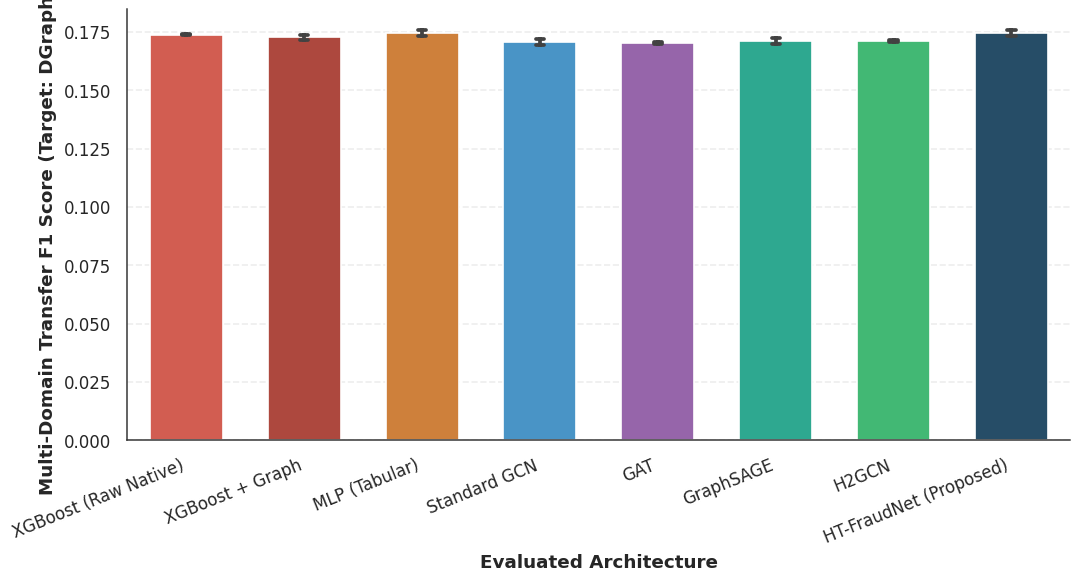

✅ lodo_dgraphfin_performance.png saved to figures/

📋 TABLE DUMP: Multi-Domain Graph Transfer Performance on DGraphFin (3-Seed Mean ± SD) (Text Version of lodo_dgraphfin_performance.png)
------------------------------------------------------------------------------------------
| Model                  | F1 (Mean ± SD)     | F1 95% CI        | Prior-Matched F1   | AUPRC (Mean ± SD)   | AUPRC 95% CI     | AUROC (Mean ± SD)   | MCC (Mean ± SD)   | ECE (Mean ± SD)   |
|:-----------------------|:-------------------|:-----------------|:-------------------|:--------------------|:-----------------|:--------------------|:------------------|:------------------|
| XGBoost (Raw Native)   | 0.1738 ± 0.0003    | [0.1736, 0.1741] | 0.1157 ± 0.0078    | 0.1032 ± 0.0001     | [0.1031, 0.1033] | 0.6829 ± 0.0001     | 0.1200 ± 0.0049   | 0.0022 ± 0.0019   |
| XGBoost + Graph        | 0.1727 ± 0.0011    | [0.1718, 0.1738] | 0.1093 ± 0.0015    | 0.1030 ± 0.0005     | [0.1025, 0.1035] | 0.6825 ± 0.0008     

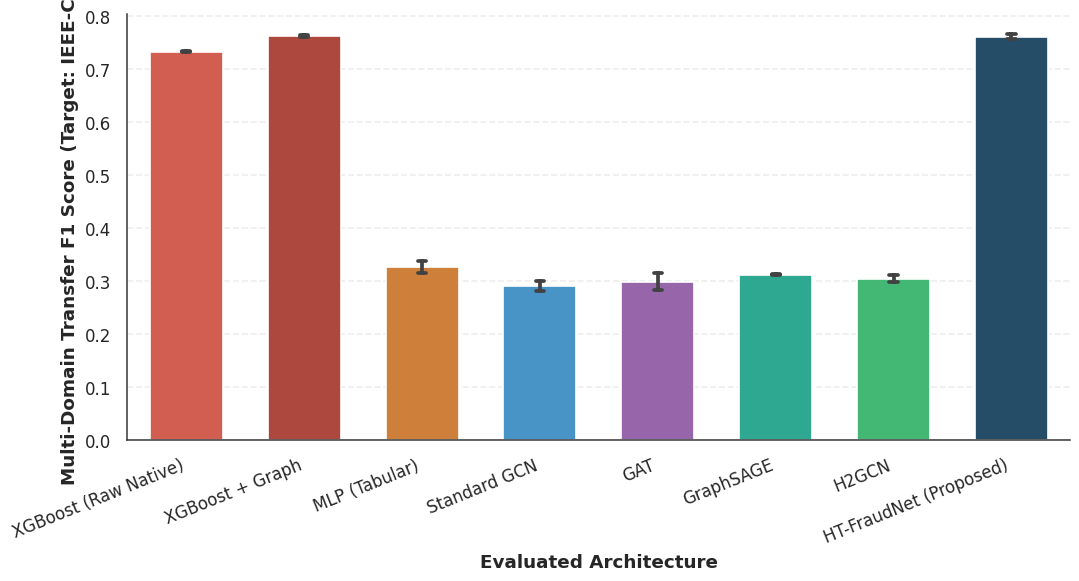

✅ lodo_ieee_performance.png saved to figures/

📋 TABLE DUMP: Multi-Domain Graph Transfer Performance on IEEE-CIS (3-Seed Mean ± SD) (Text Version of lodo_ieee_performance.png)
------------------------------------------------------------------------------------------
| Model                  | F1 (Mean ± SD)     | F1 95% CI        | Prior-Matched F1   | AUPRC (Mean ± SD)   | AUPRC 95% CI     | AUROC (Mean ± SD)   | MCC (Mean ± SD)   | ECE (Mean ± SD)   |
|:-----------------------|:-------------------|:-----------------|:-------------------|:--------------------|:-----------------|:--------------------|:------------------|:------------------|
| XGBoost (Raw Native)   | 0.7327 ± 0.0006    | [0.7319, 0.7331] | 0.7168 ± 0.0011    | 0.7744 ± 0.0001     | [0.7743, 0.7744] | 0.9564 ± 0.0002     | 0.7272 ± 0.0022   | 0.0046 ± 0.0002   |
| XGBoost + Graph        | 0.7623 ± 0.0019    | [0.7605, 0.7643] | 0.7498 ± 0.0025    | 0.8095 ± 0.0005     | [0.8090, 0.8098] | 0.9650 ± 0.0006     | 0.7586 ± 

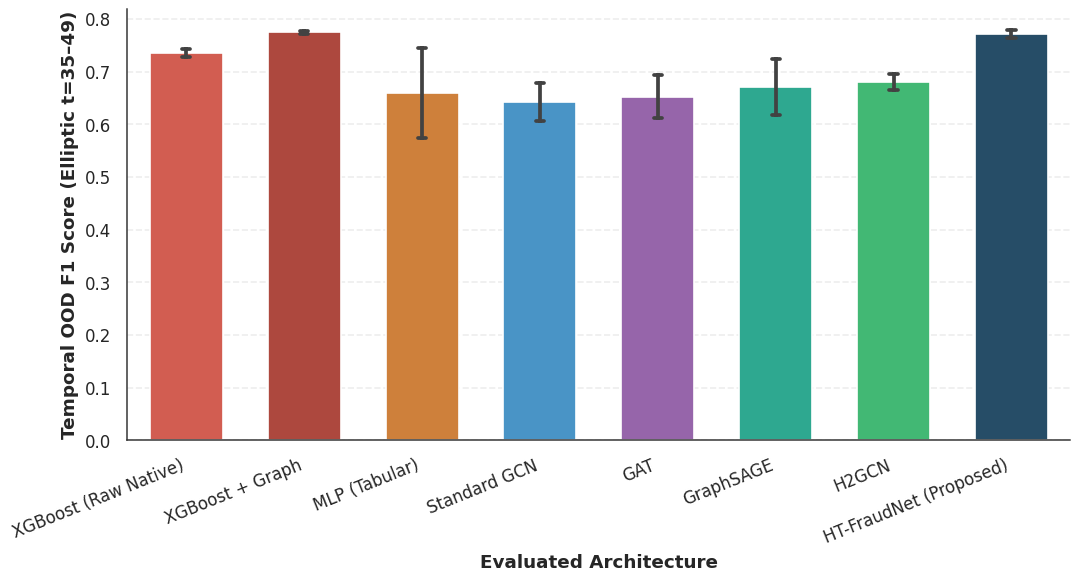

✅ temporal_ood_f1_performance.png saved to figures/

📋 TABLE DUMP: Temporal Out-of-Distribution (OOD) Generalization on Elliptic Cohort (3-Seed Mean ± SD) (Text Version of temporal_ood_f1_performance.png)
------------------------------------------------------------------------------------------
| Model                  | F1 (Mean ± SD)     | F1 95% CI        | Prior-Matched F1   | AUPRC (Mean ± SD)   | AUPRC 95% CI     | AUROC (Mean ± SD)   | MCC (Mean ± SD)   | ECE (Mean ± SD)   |
|:-----------------------|:-------------------|:-----------------|:-------------------|:--------------------|:-----------------|:--------------------|:------------------|:------------------|
| XGBoost (Raw Native)   | 0.7351 ± 0.0068    | [0.7296, 0.7427] | 0.5279 ± 0.0096    | 0.7529 ± 0.0087     | [0.7448, 0.7622] | 0.9224 ± 0.0123     | 0.7461 ± 0.0043   | 0.0150 ± 0.0011   |
| XGBoost + Graph        | 0.7749 ± 0.0029    | [0.7726, 0.7782] | 0.5407 ± 0.0090    | 0.7793 ± 0.0088     | [0.7703, 0.7879] | 0.

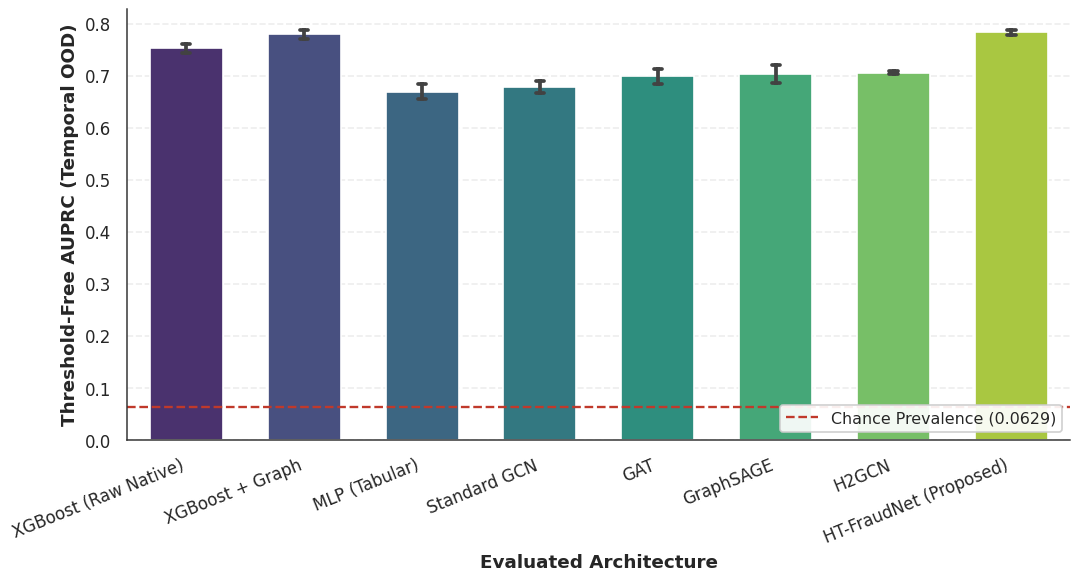

✅ temporal_ood_auprc_performance.png saved to figures/

📋 TABLE DUMP: Temporal OOD Threshold-Free AUPRC, AUROC, and Calibration Summary (Text Version of temporal_ood_auprc_performance.png)
------------------------------------------------------------------------------------------
| Model                  | AUPRC (Mean ± SD)   | AUPRC 95% CI     | AUROC (Mean ± SD)   | ECE (Mean ± SD)   |
|:-----------------------|:--------------------|:-----------------|:--------------------|:------------------|
| XGBoost (Raw Native)   | 0.7529 ± 0.0087     | [0.7448, 0.7622] | 0.9224 ± 0.0123     | 0.0150 ± 0.0011   |
| XGBoost + Graph        | 0.7793 ± 0.0088     | [0.7703, 0.7879] | 0.9370 ± 0.0049     | 0.0137 ± 0.0010   |
| MLP (Tabular)          | 0.6691 ± 0.0146     | [0.6598, 0.6860] | 0.9094 ± 0.0035     | 0.0125 ± 0.0038   |
| Standard GCN           | 0.6781 ± 0.0107     | [0.6709, 0.6904] | 0.9038 ± 0.0014     | 0.0155 ± 0.0023   |
| GAT                    | 0.6988 ± 0.0146     | [0.6851, 0.

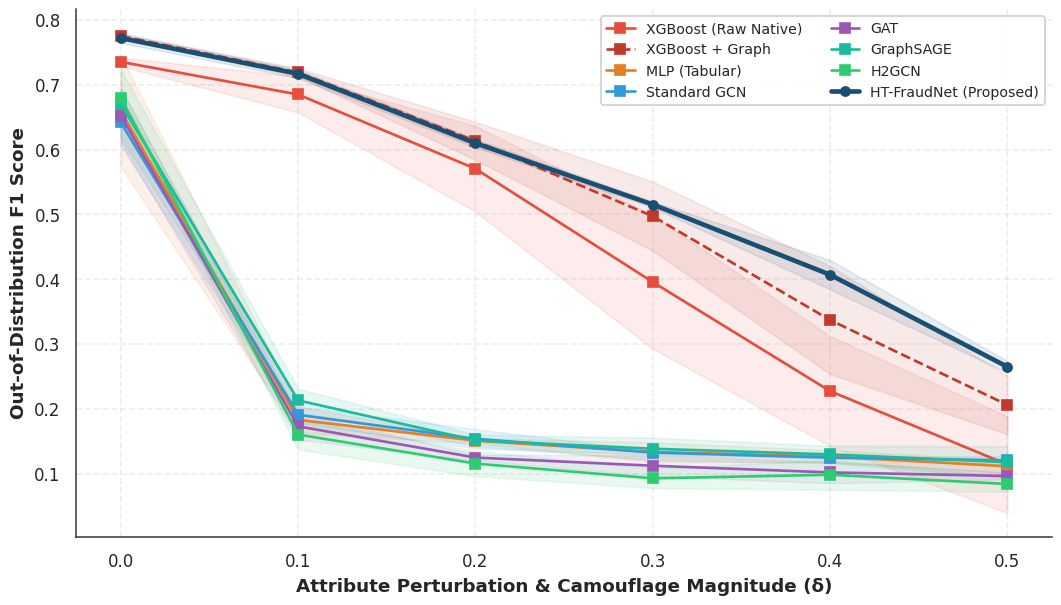

✅ adversarial_evasion_robustness_curve.png saved to figures/

📋 TABLE DUMP: Multi-Level Attribute Perturbation & Camouflage Robustness Across Magnitude δ (Text Version of adversarial_evasion_robustness_curve.png)
------------------------------------------------------------------------------------------
| Model                  | δ = 0.0         | δ = 0.1         | δ = 0.2         | δ = 0.3         | δ = 0.4         | δ = 0.5         |
|:-----------------------|:----------------|:----------------|:----------------|:----------------|:----------------|:----------------|
| XGBoost (Raw Native)   | 0.7351 ± 0.0068 | 0.6848 ± 0.0277 | 0.5703 ± 0.0661 | 0.3956 ± 0.1029 | 0.2274 ± 0.0848 | 0.1141 ± 0.0745 |
| XGBoost + Graph        | 0.7749 ± 0.0029 | 0.7188 ± 0.0064 | 0.6133 ± 0.0292 | 0.4971 ± 0.0532 | 0.3371 ± 0.0833 | 0.2060 ± 0.0449 |
| MLP (Tabular)          | 0.6590 ± 0.0859 | 0.1831 ± 0.0201 | 0.1510 ± 0.0040 | 0.1335 ± 0.0148 | 0.1268 ± 0.0096 | 0.1115 ± 0.0096 |
| Standard GCN       

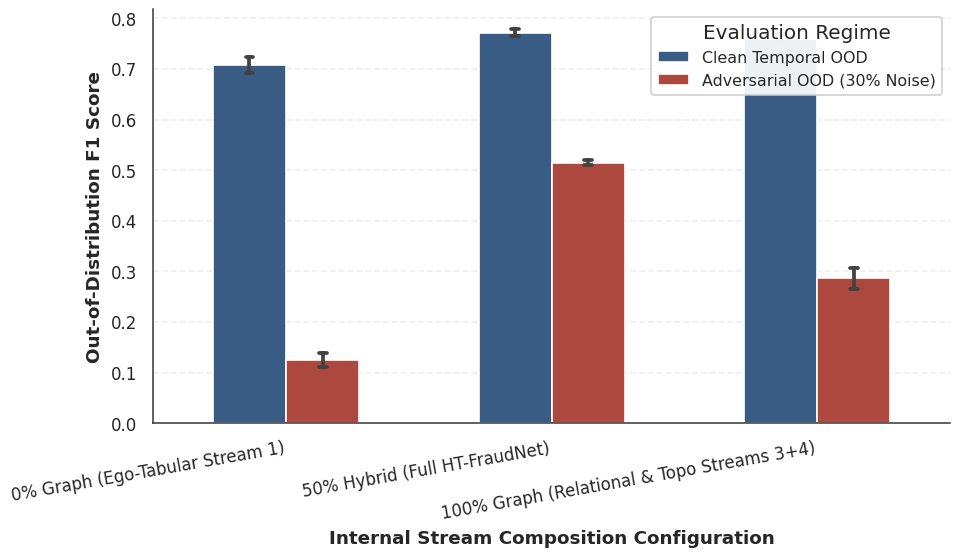

✅ modality_coupling_ratio_sweep.png saved to figures/

📋 TABLE DUMP: 3-Point Internal Stream Composition: Ego-Tabular Stream 1 (0%) vs. Full Hybrid (50%) vs. Pure Graph Streams 3+4 (100%) (Text Version of modality_coupling_ratio_sweep.png)
------------------------------------------------------------------------------------------
| Internal Stream Configuration              | Evaluation Regime           | F1 (Mean ± SD)   | AUPRC (Mean ± SD)   | MCC (Mean ± SD)   |
|:-------------------------------------------|:----------------------------|:-----------------|:--------------------|:------------------|
| 0% Graph (Ego-Tabular Stream 1)            | Adversarial OOD (30% Noise) | 0.1257 ± 0.0136  | 0.0873 ± 0.0055     | 0.0563 ± 0.0163   |
| 0% Graph (Ego-Tabular Stream 1)            | Clean Temporal OOD          | 0.7080 ± 0.0150  | 0.6649 ± 0.0062     | 0.7090 ± 0.0123   |
| 50% Hybrid (Full HT-FraudNet)              | Adversarial OOD (30% Noise) | 0.5152 ± 0.0046  | 0.5603 ± 0.0148     |

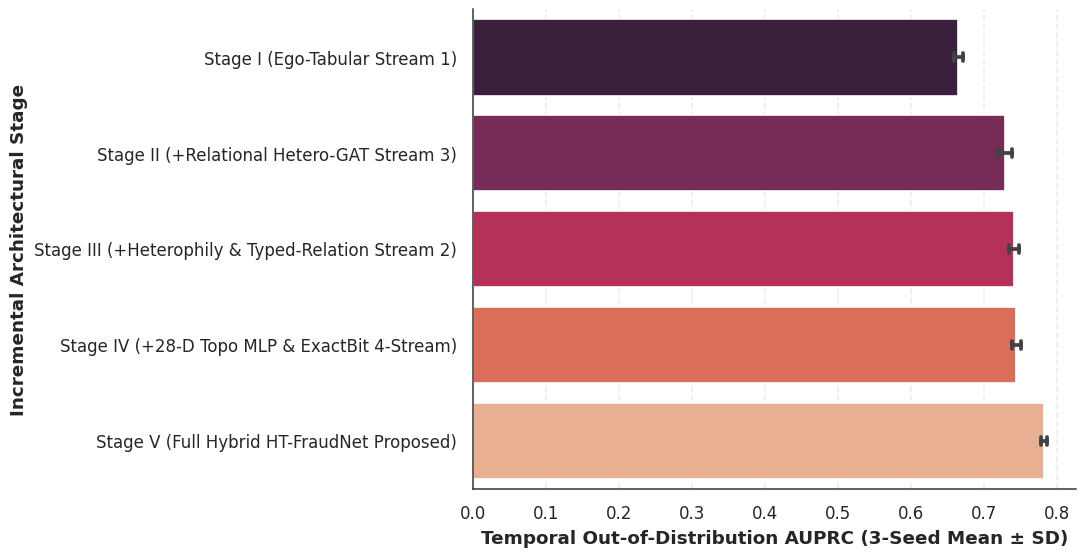

✅ progressive_ablation_ladder.png saved to figures/

📋 TABLE DUMP: 5-Stage Progressive Architectural Component Ablation Study (3-Seed Mean ± SD) (Text Version of progressive_ablation_ladder.png)
------------------------------------------------------------------------------------------
| Architectural Stage                                | AUPRC (Mean ± SD)   | F1 (Mean ± SD)   | MCC (Mean ± SD)   |
|:---------------------------------------------------|:--------------------|:-----------------|:------------------|
| Stage I (Ego-Tabular Stream 1)                     | 0.6649 ± 0.0062     | 0.7080 ± 0.0150  | 0.7090 ± 0.0123   |
| Stage II (+Relational Hetero-GAT Stream 3)         | 0.7293 ± 0.0099     | 0.7246 ± 0.0261  | 0.7329 ± 0.0200   |
| Stage III (+Heterophily & Typed-Relation Stream 2) | 0.7420 ± 0.0067     | 0.7365 ± 0.0150  | 0.7424 ± 0.0123   |
| Stage IV (+28-D Topo MLP & ExactBit 4-Stream)      | 0.7447 ± 0.0062     | 0.7364 ± 0.0209  | 0.7436 ± 0.0150   |
| Stage V (Full Hy

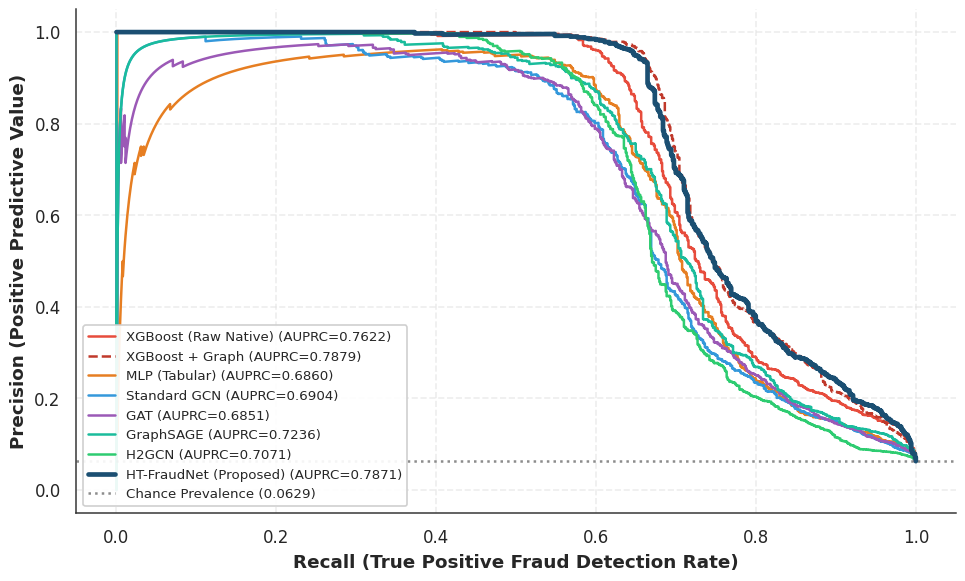

✅ temporal_ood_pr_curves.png saved to figures/

📋 TABLE DUMP: Temporal OOD Precision-Recall Curve Summary Metrics (Text Version of temporal_ood_pr_curves.png)
------------------------------------------------------------------------------------------
| Architecture           |   Temporal OOD AUPRC |   Temporal OOD F1 |   Temporal OOD MCC |   Validation Operating Threshold |
|:-----------------------|---------------------:|------------------:|-------------------:|---------------------------------:|
| XGBoost (Raw Native)   |               0.7622 |            0.7296 |             0.7417 |                           0.4926 |
| XGBoost + Graph        |               0.7879 |            0.774  |             0.7803 |                           0.3806 |
| MLP (Tabular)          |               0.686  |            0.7143 |             0.7166 |                           0.3362 |
| Standard GCN           |               0.6904 |            0.675  |             0.6767 |                           0.3

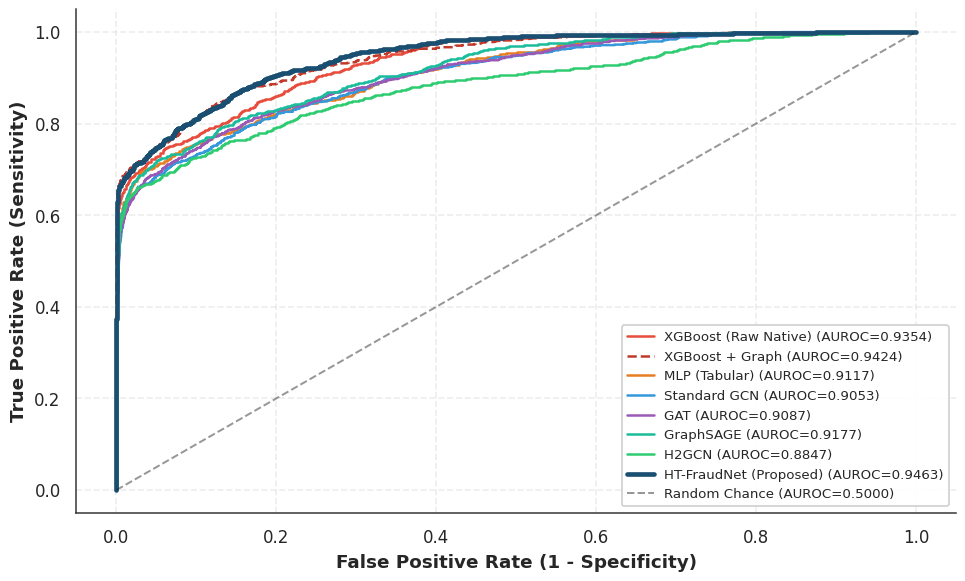

✅ temporal_ood_roc_curves.png saved to figures/

📋 TABLE DUMP: Temporal OOD Receiver Operating Characteristic (ROC) Summary Metrics (Text Version of temporal_ood_roc_curves.png)
------------------------------------------------------------------------------------------
| Architecture           |   Temporal OOD AUROC |   Temporal OOD AUPRC |   Temporal OOD F1 |   Expected Calibration Error (ECE) |
|:-----------------------|---------------------:|---------------------:|------------------:|-----------------------------------:|
| XGBoost (Raw Native)   |               0.9354 |               0.7622 |            0.7296 |                             0.0151 |
| XGBoost + Graph        |               0.9424 |               0.7879 |            0.774  |                             0.0143 |
| MLP (Tabular)          |               0.9117 |               0.686  |            0.7143 |                             0.0082 |
| Standard GCN           |               0.9053 |               0.6904 |         

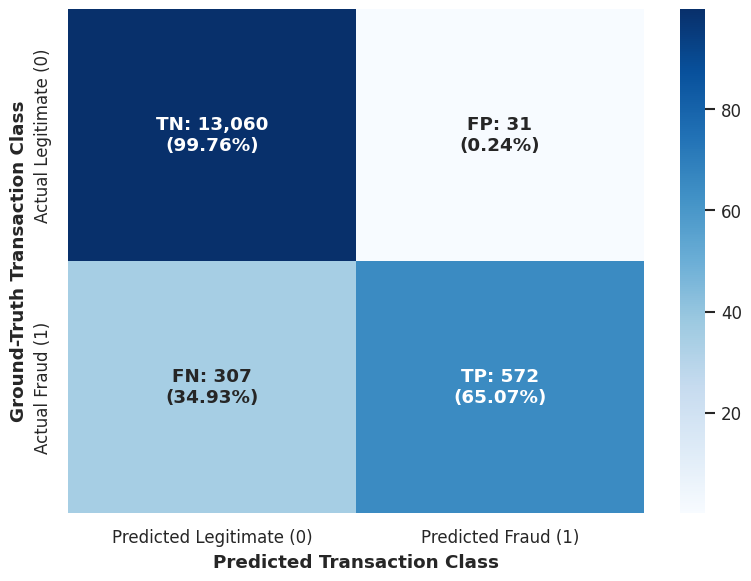

✅ temporal_ood_confusion_matrix.png saved to figures/

📋 TABLE DUMP: 3-Seed Averaged Temporal OOD Confusion Matrix Comparison Across All 8 Architectures (Text Version of temporal_ood_confusion_matrix.png)
------------------------------------------------------------------------------------------
| Model                  |    TN |   FP |   FN |   TP |   False Alarm Rate (%) |   Fraud Recall (%) |   Precision (%) |
|:-----------------------|------:|-----:|-----:|-----:|-----------------------:|-------------------:|----------------:|
| XGBoost (Raw Native)   | 13074 |   17 |  358 |  521 |                   0.13 |              59.27 |           96.84 |
| XGBoost + Graph        | 13067 |   24 |  308 |  571 |                   0.18 |              64.96 |           95.97 |
| MLP (Tabular)          | 13041 |   50 |  417 |  462 |                   0.38 |              52.56 |           90.23 |
| Standard GCN           | 13029 |   62 |  433 |  446 |                   0.47 |              50.74 |   

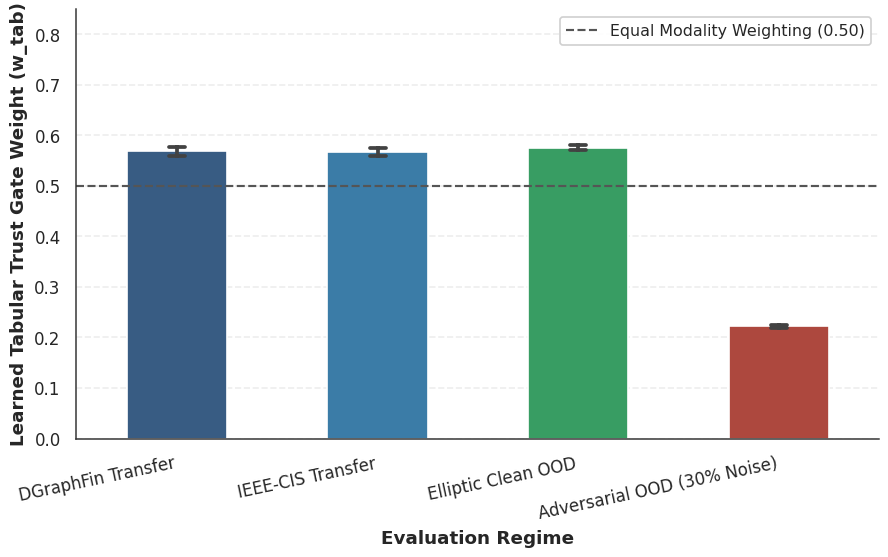

✅ adaptive_tabular_trust_weights.png saved to figures/

📋 TABLE DUMP: XAI Learned Adaptive Tabular vs. Topological Graph Trust Weights Across Regimes (Text Version of adaptive_tabular_trust_weights.png)
------------------------------------------------------------------------------------------
| Scenario                    | Tabular Trust Weight w_tab (Mean ± SD)   | Topological Graph Weight 1 - w_tab (Mean ± SD)   |
|:----------------------------|:-----------------------------------------|:-------------------------------------------------|
| Adversarial OOD (30% Noise) | 0.2218 ± 0.0022                          | 0.7782 ± 0.0022                                  |
| DGraphFin Transfer          | 0.5689 ± 0.0090                          | 0.4311 ± 0.0090                                  |
| Elliptic Clean OOD          | 0.5759 ± 0.0050                          | 0.4241 ± 0.0050                                  |
| IEEE-CIS Transfer           | 0.5681 ± 0.0079                          | 0

In [7]:
# ==============================================================================
# CELL 7
# ==============================================================================
print("🎨 GENERATING STANDALONE TITLE-FREE PUBLICATION FIGURES (FIGS 5-15)...\n")

MODEL_PALETTE = {
    'XGBoost (Raw Native)': '#e74c3c',
    'XGBoost + Graph': '#c0392b',
    'MLP (Tabular)': '#e67e22',
    'Standard GCN': '#3498db',
    'GAT': '#9b59b6',
    'GraphSAGE': '#1abc9c',
    'H2GCN': '#2ecc71',
    'HT-FraudNet (Proposed)': '#1b4f72'
}

def build_scenario_summary_table(df_scen, chance_prev_val):
    rows = []
    for m_name in MODEL_ORDER:
        sub = df_scen[df_scen['Model'] == m_name]
        if len(sub) == 0:
            continue
        f1_l, f1_h = bootstrap_ci(sub['F1'].values)
        ap_l, ap_h = bootstrap_ci(sub['AUPRC'].values)
        rows.append({
            'Model': m_name,
            'F1 (Mean ± SD)': f"{sub['F1'].mean():.4f} ± {sub['F1'].std():.4f}",
            'F1 95% CI': f"[{f1_l:.4f}, {f1_h:.4f}]",
            'Prior-Matched F1': f"{sub['Prior_F1'].mean():.4f} ± {sub['Prior_F1'].std():.4f}",
            'AUPRC (Mean ± SD)': f"{sub['AUPRC'].mean():.4f} ± {sub['AUPRC'].std():.4f}",
            'AUPRC 95% CI': f"[{ap_l:.4f}, {ap_h:.4f}]",
            'AUROC (Mean ± SD)': f"{sub['AUROC'].mean():.4f} ± {sub['AUROC'].std():.4f}",
            'MCC (Mean ± SD)': f"{sub['MCC'].mean():.4f} ± {sub['MCC'].std():.4f}",
            'ECE (Mean ± SD)': f"{sub['ECE'].mean():.4f} ± {sub['ECE'].std():.4f}"
        })
    triv_f1 = 2.0 * chance_prev_val / (1.0 + chance_prev_val)
    rows.append({
        'Model': 'Chance / Trivial Floor',
        'F1 (Mean ± SD)': f"{triv_f1:.4f} (All-Fraud)",
        'F1 95% CI': '-',
        'Prior-Matched F1': f"{chance_prev_val:.4f}",
        'AUPRC (Mean ± SD)': f"{chance_prev_val:.4f} (Prevalence)",
        'AUPRC 95% CI': '-',
        'AUROC (Mean ± SD)': '0.5000 (Random)',
        'MCC (Mean ± SD)': '0.0000',
        'ECE (Mean ± SD)': '-'
    })
    return pd.DataFrame(rows)

fig_name5 = "lodo_dgraphfin_performance.png"
df_dg_sub = df_results[df_results['Scenario'] == 'Cross-Domain Transfer (DGraphFin)'].copy()
df_dg_table = build_scenario_summary_table(df_dg_sub, chance_prev_val=0.0620)

plt.figure(figsize=(9.2, 5.0))
sns.barplot(
    data=df_dg_sub, x='Model', y='F1', order=MODEL_ORDER,
    palette=MODEL_PALETTE, errorbar='sd', capsize=0.07, width=0.62
)
plt.xticks(rotation=22, ha='right')
plt.xlabel("Evaluated Architecture")
plt.ylabel("Multi-Domain Transfer F1 Score (Target: DGraphFin)")
sns.despine()
plt.tight_layout()

save_show_and_dump(fig_name5, [
    (f"Multi-Domain Graph Transfer Performance on DGraphFin (3-Seed Mean ± SD) (Text Version of {fig_name5})", df_dg_table)
])

fig_name6 = "lodo_ieee_performance.png"
df_ie_sub = df_results[df_results['Scenario'] == 'Cross-Domain Transfer (IEEE-CIS)'].copy()
df_ie_table = build_scenario_summary_table(df_ie_sub, chance_prev_val=0.0350)

plt.figure(figsize=(9.2, 5.0))
sns.barplot(
    data=df_ie_sub, x='Model', y='F1', order=MODEL_ORDER,
    palette=MODEL_PALETTE, errorbar='sd', capsize=0.07, width=0.62
)
plt.xticks(rotation=22, ha='right')
plt.xlabel("Evaluated Architecture")
plt.ylabel("Multi-Domain Transfer F1 Score (Target: IEEE-CIS)")
sns.despine()
plt.tight_layout()

save_show_and_dump(fig_name6, [
    (f"Multi-Domain Graph Transfer Performance on IEEE-CIS (3-Seed Mean ± SD) (Text Version of {fig_name6})", df_ie_table)
])

fig_name7 = "temporal_ood_f1_performance.png"
df_ood_sub = df_results[df_results['Scenario'] == 'Temporal OOD (Elliptic)'].copy()
chance_prev = float(CURVE_DATA['HT-FraudNet (Proposed)'][0].mean())
df_ood_table = build_scenario_summary_table(df_ood_sub, chance_prev_val=chance_prev)

plt.figure(figsize=(9.2, 5.0))
sns.barplot(
    data=df_ood_sub, x='Model', y='F1', order=MODEL_ORDER,
    palette=MODEL_PALETTE, errorbar='sd', capsize=0.07, width=0.62
)
plt.xticks(rotation=22, ha='right')
plt.xlabel("Evaluated Architecture")
plt.ylabel("Temporal OOD F1 Score (Elliptic t=35–49)")
sns.despine()
plt.tight_layout()

save_show_and_dump(fig_name7, [
    (f"Temporal Out-of-Distribution (OOD) Generalization on Elliptic Cohort (3-Seed Mean ± SD) (Text Version of {fig_name7})", df_ood_table)
])

fig_name8 = "temporal_ood_auprc_performance.png"

plt.figure(figsize=(9.2, 5.0))
sns.barplot(
    data=df_ood_sub, x='Model', y='AUPRC', order=MODEL_ORDER,
    palette='viridis', errorbar='sd', capsize=0.07, width=0.62
)
plt.axhline(chance_prev, color='#c0392b', linestyle='--', lw=1.4, label=f'Chance Prevalence ({chance_prev:.4f})')
plt.xticks(rotation=22, ha='right')
plt.xlabel("Evaluated Architecture")
plt.ylabel("Threshold-Free AUPRC (Temporal OOD)")
plt.legend(loc='lower right')
sns.despine()
plt.tight_layout()

save_show_and_dump(fig_name8, [
    (f"Temporal OOD Threshold-Free AUPRC, AUROC, and Calibration Summary (Text Version of {fig_name8})",
     df_ood_table[['Model', 'AUPRC (Mean ± SD)', 'AUPRC 95% CI', 'AUROC (Mean ± SD)', 'ECE (Mean ± SD)']])
])

fig_name9 = "adversarial_evasion_robustness_curve.png"
plt.figure(figsize=(9.0, 5.2))

for m_name in MODEL_ORDER:
    sub_m = df_adv_curve[df_adv_curve['Model'] == m_name]
    agg_m = sub_m.groupby('Delta')['F1'].agg(['mean', 'std']).reset_index()
    lw = 2.8 if m_name == 'HT-FraudNet (Proposed)' else 1.6
    marker = 'o' if m_name == 'HT-FraudNet (Proposed)' else 's'
    ls = '--' if m_name == 'XGBoost + Graph' else '-'
    plt.plot(agg_m['Delta'], agg_m['mean'], label=m_name, color=MODEL_PALETTE[m_name], lw=lw, linestyle=ls, marker=marker, markersize=5.5)
    plt.fill_between(agg_m['Delta'], agg_m['mean'] - agg_m['std'], agg_m['mean'] + agg_m['std'], color=MODEL_PALETTE[m_name], alpha=0.10)

plt.xlabel("Attribute Perturbation & Camouflage Magnitude (δ)")
plt.ylabel("Out-of-Distribution F1 Score")
plt.legend(loc='upper right', ncol=2, fontsize=8.5)
sns.despine()
plt.tight_layout()

adv_pivot = df_adv_curve.groupby(['Delta', 'Model'])['F1'].agg(['mean', 'std']).reset_index()
adv_pivot['F1 (Mean ± SD)'] = adv_pivot.apply(lambda r: f"{r['mean']:.4f} ± {r['std']:.4f}", axis=1)
df_adv_table = adv_pivot.pivot(index='Model', columns='Delta', values='F1 (Mean ± SD)').reindex(MODEL_ORDER).reset_index()
df_adv_table.columns = ['Model'] + [f"δ = {d:.1f}" for d in PERTURBATION_DELTAS]

save_show_and_dump(fig_name9, [
    (f"Multi-Level Attribute Perturbation & Camouflage Robustness Across Magnitude δ (Text Version of {fig_name9})", df_adv_table)
])

fig_name10 = "modality_coupling_ratio_sweep.png"
ratio_order = [
    '0% Graph (Ego-Tabular Stream 1)',
    '50% Hybrid (Full HT-FraudNet)',
    '100% Graph (Relational & Topo Streams 3+4)'
]
df_modality_sweep['Coupling Ratio'] = pd.Categorical(df_modality_sweep['Coupling Ratio'], categories=ratio_order, ordered=True)

plt.figure(figsize=(8.2, 4.8))
sns.barplot(
    data=df_modality_sweep, x='Coupling Ratio', y='F1', hue='Scenario',
    palette=['#2b5c8f', '#c0392b'], errorbar='sd', capsize=0.06, width=0.55
)
plt.xticks(rotation=10, ha='right')
plt.xlabel("Internal Stream Composition Configuration")
plt.ylabel("Out-of-Distribution F1 Score")
plt.legend(title="Evaluation Regime", loc='upper right')
sns.despine()
plt.tight_layout()

mod_agg = df_modality_sweep.groupby(['Coupling Ratio', 'Scenario'], observed=False)[['F1', 'AUPRC', 'MCC']].agg(['mean', 'std']).reset_index()
mod_rows = []
for _, r in mod_agg.iterrows():
    mod_rows.append({
        'Internal Stream Configuration': r[('Coupling Ratio', '')],
        'Evaluation Regime': r[('Scenario', '')],
        'F1 (Mean ± SD)': f"{r[('F1', 'mean')]:.4f} ± {r[('F1', 'std')]:.4f}",
        'AUPRC (Mean ± SD)': f"{r[('AUPRC', 'mean')]:.4f} ± {r[('AUPRC', 'std')]:.4f}",
        'MCC (Mean ± SD)': f"{r[('MCC', 'mean')]:.4f} ± {r[('MCC', 'std')]:.4f}"
    })
df_mod_table = pd.DataFrame(mod_rows)

save_show_and_dump(fig_name10, [
    (f"3-Point Internal Stream Composition: Ego-Tabular Stream 1 (0%) vs. Full Hybrid (50%) vs. Pure Graph Streams 3+4 (100%) (Text Version of {fig_name10})", df_mod_table)
])

fig_name11 = "progressive_ablation_ladder.png"
stage_order = [
    'Stage I (Ego-Tabular Stream 1)',
    'Stage II (+Relational Hetero-GAT Stream 3)',
    'Stage III (+Heterophily & Typed-Relation Stream 2)',
    'Stage IV (+28-D Topo MLP & ExactBit 4-Stream)',
    'Stage V (Full Hybrid HT-FraudNet Proposed)'
]
df_ablation_ladder['Stage'] = pd.Categorical(df_ablation_ladder['Stage'], categories=stage_order, ordered=True)

plt.figure(figsize=(9.2, 4.8))
sns.barplot(
    data=df_ablation_ladder, y='Stage', x='AUPRC',
    palette='rocket', errorbar='sd', capsize=0.08
)
plt.xlabel("Temporal Out-of-Distribution AUPRC (3-Seed Mean ± SD)")
plt.ylabel("Incremental Architectural Stage")
sns.despine()
plt.tight_layout()

abl_agg = df_ablation_ladder.groupby('Stage', observed=False)[['AUPRC', 'F1', 'MCC']].agg(['mean', 'std']).reset_index()
abl_rows = []
for _, r in abl_agg.iterrows():
    abl_rows.append({
        'Architectural Stage': r[('Stage', '')],
        'AUPRC (Mean ± SD)': f"{r[('AUPRC', 'mean')]:.4f} ± {r[('AUPRC', 'std')]:.4f}",
        'F1 (Mean ± SD)': f"{r[('F1', 'mean')]:.4f} ± {r[('F1', 'std')]:.4f}",
        'MCC (Mean ± SD)': f"{r[('MCC', 'mean')]:.4f} ± {r[('MCC', 'std')]:.4f}"
    })
df_abl_table = pd.DataFrame(abl_rows)

save_show_and_dump(fig_name11, [
    (f"5-Stage Progressive Architectural Component Ablation Study (3-Seed Mean ± SD) (Text Version of {fig_name11})", df_abl_table)
])

fig_name12 = "temporal_ood_pr_curves.png"
plt.figure(figsize=(8.2, 5.0))
pr_dump_rows = []

for m_name in MODEL_ORDER:
    y_t, y_p, met_c = CURVE_DATA[m_name]
    prec, rec, _ = precision_recall_curve(y_t, y_p)
    lw = 2.8 if m_name == 'HT-FraudNet (Proposed)' else 1.5
    ls = '--' if m_name == 'XGBoost + Graph' else '-'
    plt.plot(rec, prec, lw=lw, linestyle=ls, color=MODEL_PALETTE[m_name], label=f"{m_name} (AUPRC={met_c['AUPRC']:.4f})")
    pr_dump_rows.append({
        'Architecture': m_name,
        'Temporal OOD AUPRC': round(met_c['AUPRC'], 4),
        'Temporal OOD F1': round(met_c['F1'], 4),
        'Temporal OOD MCC': round(met_c['MCC'], 4),
        'Validation Operating Threshold': round(met_c['Threshold'], 4)
    })

plt.axhline(chance_prev, color='k', linestyle=':', alpha=0.5, label=f'Chance Prevalence ({chance_prev:.4f})')
plt.xlabel("Recall (True Positive Fraud Detection Rate)")
plt.ylabel("Precision (Positive Predictive Value)")
plt.legend(loc='lower left', fontsize=8.0)
sns.despine()
plt.tight_layout()

save_show_and_dump(fig_name12, [
    (f"Temporal OOD Precision-Recall Curve Summary Metrics (Text Version of {fig_name12})", pd.DataFrame(pr_dump_rows))
])

fig_name13 = "temporal_ood_roc_curves.png"
plt.figure(figsize=(8.2, 5.0))
roc_dump_rows = []

for m_name in MODEL_ORDER:
    y_t, y_p, met_c = CURVE_DATA[m_name]
    fpr, tpr, _ = roc_curve(y_t, y_p)
    lw = 2.8 if m_name == 'HT-FraudNet (Proposed)' else 1.5
    ls = '--' if m_name == 'XGBoost + Graph' else '-'
    plt.plot(fpr, tpr, lw=lw, linestyle=ls, color=MODEL_PALETTE[m_name], label=f"{m_name} (AUROC={met_c['AUROC']:.4f})")
    roc_dump_rows.append({
        'Architecture': m_name,
        'Temporal OOD AUROC': round(met_c['AUROC'], 4),
        'Temporal OOD AUPRC': round(met_c['AUPRC'], 4),
        'Temporal OOD F1': round(met_c['F1'], 4),
        'Expected Calibration Error (ECE)': round(met_c['ECE'], 4)
    })

plt.plot([0, 1], [0, 1], 'k--', alpha=0.45, lw=1.2, label='Random Chance (AUROC=0.5000)')
plt.xlabel("False Positive Rate (1 - Specificity)")
plt.ylabel("True Positive Rate (Sensitivity)")
plt.legend(loc='lower right', fontsize=8.0)
sns.despine()
plt.tight_layout()

save_show_and_dump(fig_name13, [
    (f"Temporal OOD Receiver Operating Characteristic (ROC) Summary Metrics (Text Version of {fig_name13})", pd.DataFrame(roc_dump_rows))
])

fig_name14 = "temporal_ood_confusion_matrix.png"
df_cm_all = df_ood_sub.groupby('Model')[['TN', 'FP', 'FN', 'TP']].mean().round().astype(int).reindex(MODEL_ORDER).reset_index()
df_cm_all['False Alarm Rate (%)'] = (100.0 * df_cm_all['FP'] / (df_cm_all['TN'] + df_cm_all['FP'])).round(2)
df_cm_all['Fraud Recall (%)'] = (100.0 * df_cm_all['TP'] / (df_cm_all['FN'] + df_cm_all['TP'])).round(2)
df_cm_all['Precision (%)'] = (100.0 * df_cm_all['TP'] / (df_cm_all['TP'] + df_cm_all['FP'])).round(2)

ours_cm_row = df_cm_all[df_cm_all['Model'] == 'HT-FraudNet (Proposed)'].iloc[0]
tn_o, fp_o, fn_o, tp_o = int(ours_cm_row['TN']), int(ours_cm_row['FP']), int(ours_cm_row['FN']), int(ours_cm_row['TP'])
cm_mat = np.array([[tn_o, fp_o], [fn_o, tp_o]])
cm_norm = cm_mat.astype(float) / cm_mat.sum(axis=1, keepdims=True) * 100.0
annot_mat = np.array([
    [f"TN: {tn_o:,}\n({cm_norm[0,0]:.2f}%)", f"FP: {fp_o:,}\n({cm_norm[0,1]:.2f}%)"],
    [f"FN: {fn_o:,}\n({cm_norm[1,0]:.2f}%)", f"TP: {tp_o:,}\n({cm_norm[1,1]:.2f}%)"]
])

plt.figure(figsize=(6.8, 5.0))
sns.heatmap(
    cm_norm, annot=annot_mat, fmt='', cmap='Blues', cbar=True,
    xticklabels=['Predicted Legitimate (0)', 'Predicted Fraud (1)'],
    yticklabels=['Actual Legitimate (0)', 'Actual Fraud (1)'],
    annot_kws={'size': 11, 'weight': 'bold'}
)
plt.xlabel("Predicted Transaction Class")
plt.ylabel("Ground-Truth Transaction Class")
plt.tight_layout()

save_show_and_dump(fig_name14, [
    (f"3-Seed Averaged Temporal OOD Confusion Matrix Comparison Across All 8 Architectures (Text Version of {fig_name14})", df_cm_all)
])

fig_name15 = "adaptive_tabular_trust_weights.png"
plt.figure(figsize=(7.6, 4.8))
sns.barplot(
    data=df_trust_weights, x='Scenario', y='Weight',
    palette=['#2b5c8f', '#2980b9', '#27ae60', '#c0392b'],
    errorbar='sd', capsize=0.08, width=0.50
)
plt.axhline(0.50, color='#555555', linestyle='--', lw=1.3, label='Equal Modality Weighting (0.50)')
plt.ylim(0.0, 0.85)
plt.xticks(rotation=12, ha='right')
plt.xlabel("Evaluation Regime")
plt.ylabel("Learned Tabular Trust Gate Weight (w_tab)")
plt.legend(loc='upper right')
sns.despine()
plt.tight_layout()

tw_agg = df_trust_weights.groupby('Scenario')['Weight'].agg(['mean', 'std']).reset_index()
tw_agg['Tabular Trust Weight w_tab (Mean ± SD)'] = tw_agg.apply(lambda r: f"{r['mean']:.4f} ± {r['std']:.4f}", axis=1)
tw_agg['Topological Graph Weight 1 - w_tab (Mean ± SD)'] = tw_agg.apply(lambda r: f"{1.0 - r['mean']:.4f} ± {r['std']:.4f}", axis=1)

save_show_and_dump(fig_name15, [
    (f"XAI Learned Adaptive Tabular vs. Topological Graph Trust Weights Across Regimes (Text Version of {fig_name15})",
     tw_agg[['Scenario', 'Tabular Trust Weight w_tab (Mean ± SD)', 'Topological Graph Weight 1 - w_tab (Mean ± SD)']])
])

---

### **CELL 8: Archive Verification & Universal Auto-Download**

In [8]:
# ==============================================================================
# CELL 8
# ==============================================================================
import shutil

archive_name = 'HTFraudNet_Publication_Figures'
zip_filename = f"{archive_name}.zip"

shutil.make_archive(archive_name, 'zip', FIGURES_DIR)
saved_pngs = sorted([p.name for p in FIGURES_DIR.glob("*.png")])
print(f"✅ Successfully created {zip_filename} containing all {len(saved_pngs)} high-res publication figures:")
for idx_f, f_n in enumerate(saved_pngs, 1):
    print(f"   {idx_f:02d}. {f_n}")

try:
    from google.colab import files
    files.download(zip_filename)
    print(f"⬇️ Triggered single download of {zip_filename}.")
except Exception as e:
    print(f"ZIP saved locally at {zip_filename} (auto-download skipped: {e})")

✅ Successfully created HTFraudNet_Publication_Figures.zip containing all 15 high-res publication figures:
   01. adaptive_tabular_trust_weights.png
   02. adversarial_evasion_robustness_curve.png
   03. cohort_class_imbalance.png
   04. cross_domain_feature_shift_eda.png
   05. graph_heterophily_trap_eda.png
   06. lodo_dgraphfin_performance.png
   07. lodo_ieee_performance.png
   08. modality_coupling_ratio_sweep.png
   09. progressive_ablation_ladder.png
   10. temporal_ood_auprc_performance.png
   11. temporal_ood_confusion_matrix.png
   12. temporal_ood_f1_performance.png
   13. temporal_ood_pr_curves.png
   14. temporal_ood_roc_curves.png
   15. topological_biomarker_eda.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

⬇️ Triggered single download of HTFraudNet_Publication_Figures.zip.


In [9]:
# =======================================================
# CELL 9: INSTANT OUTPUT EXTRACTOR & AUTO-DOWNLOAD
# =======================================================
from google.colab import _message, files

def extract_and_download_outputs(output_filename="ht-fraudnet-output.txt"):
    try:
        response = _message.blocking_request('get_ipynb', request='', timeout_sec=5)
        notebook = response.get('ipynb', {})

        output_content = []
        cells = notebook.get("cells", [])

        for i, cell in enumerate(cells):
            if "outputs" in cell and cell["outputs"]:
                cell_text = []
                for output in cell["outputs"]:
                    out_type = output.get("output_type")
                    if out_type == "stream":
                        text = output.get("text", "")
                        if isinstance(text, list):
                            text = "".join(text)
                        cell_text.append(text)
                    elif out_type in ["execute_result", "display_data"]:
                        data = output.get("data", {})
                        if "text/plain" in data:
                            text = data["text/plain"]
                            if isinstance(text, list):
                                text = "".join(text)
                            cell_text.append(text)
                    elif out_type == "error":
                        traceback = output.get("traceback", [])
                        if isinstance(traceback, list):
                            cell_text.append("\n".join(traceback))
                        else:
                            cell_text.append(f"{output.get('ename')}: {output.get('evalue')}")

                if cell_text:
                    raw_joined_text = "".join(cell_text)
                    clean_text = raw_joined_text.replace("<IPython.core.display.Javascript object>", "").strip()
                    if clean_text and "INSTANT OUTPUT EXTRACTOR" not in "".join(cell.get("source", [])):
                        output_content.append(f"--- Cell {i + 1} Outputs ---")
                        output_content.append(clean_text)
                        output_content.append("")

        with open(output_filename, 'w', encoding='utf-8') as f:
            f.write("\n".join(output_content))

        print(f"✅ Extracted full console outputs into '{output_filename}'.")
        print("⬇️ Triggering instant download of output.txt...")
        files.download(output_filename)

    except Exception as e:
        print(f"Extraction failed: {e}")

extract_and_download_outputs()

def _delayed_runtime_release(wait_sec=60):
    time.sleep(wait_sec)
    try:
        from google.colab import runtime
        runtime.unassign()
    except Exception:
        pass

threading.Thread(target=_delayed_runtime_release, args=(60,), daemon=True).start()
print("⏳ Main kernel thread is now IDLE so your .zip downloads immediately.")
print("🛑 A background thread will automatically release the Colab GPU runtime in 60 seconds.")

✅ Extracted full console outputs into 'ht-fraudnet-output.txt'.
⬇️ Triggering instant download of output.txt...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

⏳ Main kernel thread is now IDLE so your .zip downloads immediately.
🛑 A background thread will automatically release the Colab GPU runtime in 60 seconds.
